# UNIVERSIDAD PERUANA CAYETANO HEREDIA
# SEÑALES BIOMÉDICAS
## LAB 7 — Filtrado de señales II: Filtros adaptativos y Transformada Wavelet

**Curso:** Introducción a las Señales Biomédicas
**Modalidad:** Jupyter Notebook / Google Colab
**Tema:** Filtrado de señales II — Filtros adaptativos (LMS) y Transformada Wavelet aplicados a ECG
**Laboratorio práctico · Duración:** 2 horas (120 min)

| Campo | Completar |
|---|---|
| Nombre del estudiante | ✍️ |
| Código | ✍️ |
| Fecha | ✍️ |

> **Enfoque del laboratorio:** *"Primero observamos la señal, luego la contaminamos, analizamos cómo se degrada, aplicamos diferentes técnicas de filtrado y finalmente evaluamos qué ocurrió con la señal."*

## 🎯 Resultados de aprendizaje

Al finalizar el laboratorio, serás capaz de:

1. Identificar una señal ECG en datos adquiridos mediante **BITalino (r)evolution / OpenSignals**.
2. Diferenciar **señal fisiológica**, **interferencia** y **ruido**.
3. Generar artificialmente señales contaminadas de forma controlada.
4. Aplicar filtros digitales (pasa-banda y notch).
5. Comparar métodos de filtrado con criterios visuales y cuantitativos.
6. Comprender conceptualmente el **filtrado adaptativo** (algoritmo LMS).
7. Comprender para qué sirve la **Transformada Wavelet**.
8. Evaluar la recuperación de una señal ECG.
9. Comunicar los resultados mediante una **infografía**.

## ⏱️ Agenda de la sesión (120 min)

| Bloque | Contenido | Duración | Minutos |
|---|---|---:|---:|
| 1 | Introducción y exploración de datos | 15 min | 0 – 15 |
| 2 | Señal ECG original | 15 min | 15 – 30 |
| 3 | Contaminación artificial + análisis en frecuencia | 20 min | 30 – 50 |
| 4 | Aplicación de filtros convencionales + métricas | 25 min | 50 – 75 |
| 5 | Filtros adaptativos y Wavelet | 20 min | 75 – 95 |
| 6 | Comparación e interpretación | 10 min | 95 – 105 |
| 7 | Retroalimentación, síntesis e infografía | 15 min | 105 – 120 |

> 🔁 **Los últimos 30 minutos (min 90 – 120)** se dedican a **revisión, discusión y retroalimentación**: cierre de la discusión Wavelet, comparación global (Bloque 6), preguntas, síntesis *SUMARIZE* e infografía (Bloque 7). En este tramo **no se introducen conceptos nuevos**.

**Patrón de trabajo en cada sección:**

```
CONCEPTO → EXPLICACIÓN BREVE → CÓDIGO → GRÁFICA → INTERPRETACIÓN → PREGUNTA AL ESTUDIANTE
```

---
# 🟦 BLOQUE 1 — Introducción y exploración de datos *(15 min)*

## 1.1 Librerías

| Librería | Para qué la usamos |
|---|---|
| `numpy` | Operaciones numéricas con vectores: eje temporal, senoides, ruido, FFT. |
| `pandas` | Leer el archivo de texto como tabla y explorar columnas/estadísticas. |
| `matplotlib` | Graficar señales en tiempo y frecuencia. |
| `scipy.signal` | Diseñar y aplicar filtros digitales (`butter`, `iirnotch`, `filtfilt`, `freqz`). |
| `pywt` (PyWavelets) | Transformada Wavelet discreta: descomposición y denoising. |

In [1]:
# Si trabajas en Google Colab y PyWavelets no está instalado, descomenta la siguiente línea:
# !pip install PyWavelets

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
import pywt

# Estilo de gráficos uniforme para todo el laboratorio
plt.rcParams.update({
    "figure.figsize": (14, 4),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titleweight": "bold",
    "font.size": 11,
})

# Semilla: garantiza que el ruido "aleatorio" sea el mismo en cada ejecución (reproducibilidad)
rng = np.random.default_rng(seed=42)

print("NumPy:", np.__version__, "| Pandas:", pd.__version__, "| PyWavelets:", pywt.__version__)

NumPy: 2.5.3 | Pandas: 3.0.5 | PyWavelets: 1.8.0


## 1.2 El archivo `SampleECG.txt` (formato OpenSignals)

Un archivo exportado por OpenSignals tiene dos partes:

1. **Cabecera:** líneas que comienzan con `#`. Una de ellas contiene un diccionario JSON con los metadatos de adquisición (frecuencia de muestreo, resolución, nombres de columnas, etc.).
2. **Datos:** una fila por muestra, con columnas separadas por tabulaciones.

| Columna | Significado | ¿Es ECG? |
|---|---|---|
| `nSeq` | Contador de secuencia de paquetes | ❌ |
| `I1`, `I2` | Entradas digitales | ❌ |
| `O1`, `O2` | Salidas digitales | ❌ |
| `A2` | Canal analógico con el sensor ECG | ✅ |

Primero aseguramos que el archivo esté disponible (en Colab se puede subir desde la computadora).

In [2]:
RUTA_ARCHIVO = "basal1.txt"

if not os.path.exists(RUTA_ARCHIVO):
    try:
        from google.colab import files   # Solo existe en Google Colab
        print("Selecciona el archivo SampleECG.txt desde tu computadora...")
        files.upload()
    except ImportError:
        print(f"⚠️ No se encontró '{RUTA_ARCHIVO}'. Colócalo en la misma carpeta que este notebook.")

print("¿Archivo disponible?:", os.path.exists(RUTA_ARCHIVO))

¿Archivo disponible?: True


### Leer la cabecera

Leemos solo las líneas iniciales que empiezan con `#` y extraemos los metadatos directamente del archivo (no los suponemos).

In [3]:
# 1) Guardar las líneas de cabecera (empiezan con '#')
lineas_cabecera = []
with open(RUTA_ARCHIVO, "r", encoding="utf-8", errors="ignore") as archivo:
    for linea in archivo:
        if linea.startswith("#"):
            lineas_cabecera.append(linea.strip())
        else:
            break   # termina la cabecera, empiezan los datos

print("Cabecera del archivo:\n")
for linea in lineas_cabecera:
    print(linea[:300] + ("..." if len(linea) > 300 else ""))

# 2) Buscar la línea JSON con los metadatos del dispositivo
metadatos = {}
for linea in lineas_cabecera:
    contenido = linea.lstrip("#").strip()
    if contenido.startswith("{"):
        try:
            diccionario = json.loads(contenido)
            metadatos = list(diccionario.values())[0]   # primer dispositivo (identificado por su MAC)
        except json.JSONDecodeError:
            print("No se pudo interpretar el JSON de la cabecera.")

# 3) Extraer los parámetros relevantes (con valores por defecto si faltaran)
Fs = int(metadatos.get("sampling rate", 1000))
columnas = metadatos.get("column", ["nSeq", "I1", "I2", "O1", "O2", "A2"])
resoluciones = metadatos.get("resolution", [])

# Canal con el ECG: 'A2' según este laboratorio. Algunas exportaciones de OpenSignals nombran
# a ese mismo canal 'A1' (p. ej. el basal1.txt del laboratorio 4), por eso, si 'A2' no existe,
# se toma el primer canal analógico declarado en la cabecera.
canal_ecg = "A2" if "A2" in columnas else next(c for c in columnas if c.startswith("A"))
resolucion_A2 = resoluciones[columnas.index(canal_ecg)] if len(resoluciones) == len(columnas) else 10

print("\nFrecuencia de muestreo (Fs):", Fs, "Hz")
print("Columnas:", columnas)
print(f"Canal ECG usado: {canal_ecg}")
print("Resolución del canal A2:", resolucion_A2, "bits")

Cabecera del archivo:

# OpenSignals Text File Format. Version 1
# {"98:D3:41:FE:16:36": {"position": 0, "device": "bitalino_rev", "device name": "98:D3:41:FE:16:36", "device connection": "BTH98:D3:41:FE:16:36", "sampling rate": 1000, "resolution": [4, 1, 1, 1, 1, 10], "firmware version": 1282, "comments": "", "keywords": "", "mode": 0, "sync interval": 2, "date"...
# EndOfHeader

Frecuencia de muestreo (Fs): 1000 Hz
Columnas: ['nSeq', 'I1', 'I2', 'O1', 'O2', 'A1']
Canal ECG usado: A1
Resolución del canal A2: 10 bits


### Leer los datos

In [4]:
# comment="#" ignora la cabecera; sep=r"\s+" admite tabulaciones (y tabulaciones finales)
datos = pd.read_csv(RUTA_ARCHIVO, sep=r"\s+", comment="#", header=None)
datos = datos.iloc[:, :len(columnas)]      # nos quedamos solo con las columnas declaradas
datos.columns = columnas

numero_muestras = len(datos)
Ts = 1 / Fs                                # periodo de muestreo
duracion_total = numero_muestras / Fs

print(f"Número de muestras : {numero_muestras}")
print(f"Frecuencia muestreo: {Fs} Hz")
print(f"Periodo de muestreo: {Ts*1000:.1f} ms")
print(f"Duración total    : {duracion_total:.2f} s")
print(f"Columnas          : {list(datos.columns)}")
datos.head(10)

Número de muestras : 34650
Frecuencia muestreo: 1000 Hz
Periodo de muestreo: 1.0 ms
Duración total    : 34.65 s
Columnas          : ['nSeq', 'I1', 'I2', 'O1', 'O2', 'A1']


,nSeq,I1,I2,O1,O2,A1
0,0,0,0,0,0,503
1,1,0,0,0,0,502
2,2,0,0,0,0,504
3,3,0,0,0,0,504
4,4,0,0,0,0,505
5,5,0,0,0,0,507
6,6,0,0,0,0,507
7,7,0,0,0,0,507
8,8,0,0,0,0,507
9,9,0,0,0,0,506


In [5]:
# Estadísticas básicas de todas las columnas
datos.describe().T

,count,mean,std,min,25%,50%,75%,max
nSeq,34650.0,7.499134,4.609713,0.0,3.0,7.0,11.0,15.0
I1,34650.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
I2,34650.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
O1,34650.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
O2,34650.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
A1,34650.0,508.978557,27.266977,388.0,500.0,510.0,520.0,643.0


### ¿Por qué **no** usar `nSeq` como eje temporal?

`nSeq` es un **contador de paquetes** que se reinicia periódicamente (en BITalino es un contador de 4 bits: 0, 1, …, 15, 0, 1, …). Sirve para **detectar muestras perdidas** durante la transmisión, pero **no** es el tiempo absoluto. El eje temporal correcto se construye a partir del índice de muestra y la frecuencia de muestreo:

$$t[n] = \frac{n}{F_s}$$

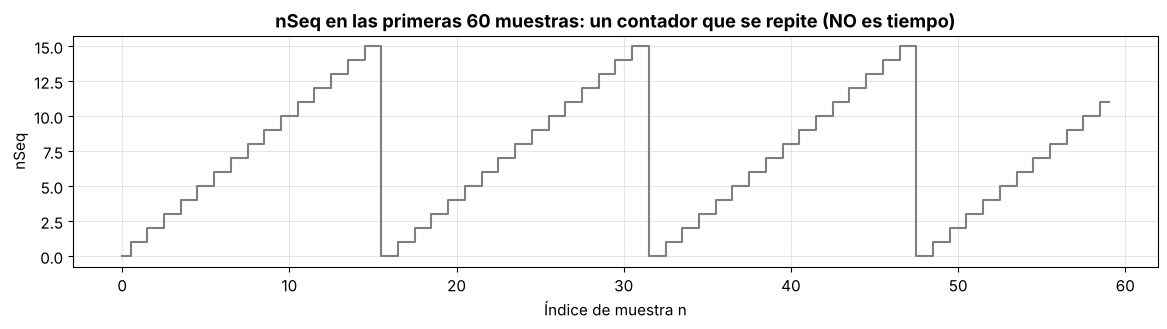

El contador va de 0 a 15.
Muestras con salto distinto de 1 (posibles pérdidas): 0


In [6]:
fig, ax = plt.subplots(figsize=(14, 3))
ax.step(np.arange(60), datos["nSeq"].values[:60], where="mid", color="tab:gray")
ax.set_title("nSeq en las primeras 60 muestras: un contador que se repite (NO es tiempo)")
ax.set_xlabel("Índice de muestra n"); ax.set_ylabel("nSeq")
plt.show()

# Verificación de paquetes perdidos: el salto esperado entre muestras consecutivas es 1 (módulo del contador)
modulo = int(datos["nSeq"].max()) + 1
saltos = np.diff(datos["nSeq"].values) % modulo
print(f"El contador va de 0 a {modulo-1}.")
print("Muestras con salto distinto de 1 (posibles pérdidas):", int(np.sum(saltos != 1)))

### ❓ Pregunta al estudiante (Bloque 1)

Según la cabecera, ¿cuántos niveles distintos puede tomar el canal `A2`? (Pista: $2^{\text{bits}}$). ¿Por qué es útil verificar `nSeq` antes de analizar la señal?

✍️ **Respuesta:**

- Según la cabecera, `A2` tiene resolución de **10 bits**, así que puede tomar $2^{10} = 1024$ niveles distintos (valores de 0 a 1023).
- Verificar `nSeq` antes de analizar sirve para comprobar que **no se perdieron paquetes** durante la transmisión: el contador (0–15) debe avanzar de 1 en 1. Aquí hay **0 saltos anómalos** en 34 650 muestras, así que el eje $t = n/F_s$ es confiable (34.65 s sin huecos).

---
# 🟦 BLOQUE 2 — Señal ECG original *(15 min)*

## 2.1 Conceptos mínimos

- **Amplitud:** magnitud de la señal (aquí, en mV).
- **Tiempo:** eje horizontal construido con $t = n/F_s$.
- **Frecuencia de muestreo** $F_s$: muestras por segundo (1000 Hz → 1000 muestras/s).
- **Periodo de muestreo** $T_s = 1/F_s$: tiempo entre muestras (1 ms).
- **Morfología ECG:** forma característica de cada latido (onda P, complejo QRS, onda T).
- **Ruido:** componente aleatoria, no deseada, generalmente de banda ancha.
- **Interferencia:** componente no deseada con origen y estructura identificables (p. ej., la red eléctrica a una frecuencia fija).

## 2.2 Extraer `A2` y convertir a milivoltios

El canal `A2` contiene valores del conversor analógico-digital (ADC). Para expresarlos en mV usamos la función de transferencia del sensor ECG de BITalino (hoja de datos del fabricante):

$$ECG_{mV} = \left(\frac{ADC}{2^{n}} - \frac{1}{2}\right)\cdot\frac{V_{CC}}{G_{ECG}}\cdot 1000,\qquad V_{CC}=3.3\ \text{V},\quad G_{ECG}=1100$$

Si tu sensor fuera distinto, puedes trabajar directamente en unidades ADC: los filtros funcionan igual.

In [7]:
VCC = 3.3        # voltaje de operación (V)
G_ECG = 1100     # ganancia del sensor ECG de BITalino

ecg_adc = datos[canal_ecg].to_numpy(dtype=float)   # canal A2 (o el analógico equivalente, ver arriba)
ecg_mV = ((ecg_adc / 2**resolucion_A2) - 0.5) * VCC / G_ECG * 1000

# Señal de referencia del laboratorio: ECG REAL centrado en cero (restamos la media)
ecg_original = ecg_mV - np.mean(ecg_mV)

# Eje temporal correcto
t = np.arange(len(ecg_original)) / Fs

print(f"Amplitud mínima: {ecg_original.min():.3f} mV | máxima: {ecg_original.max():.3f} mV")
print(f"Desviación estándar: {np.std(ecg_original):.3f} mV")

Amplitud mínima: -0.354 mV | máxima: 0.393 mV
Desviación estándar: 0.080 mV


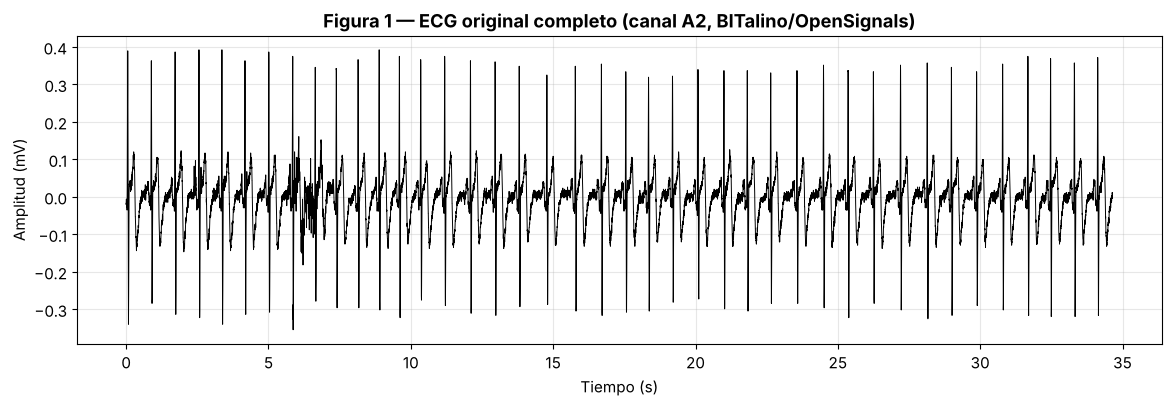

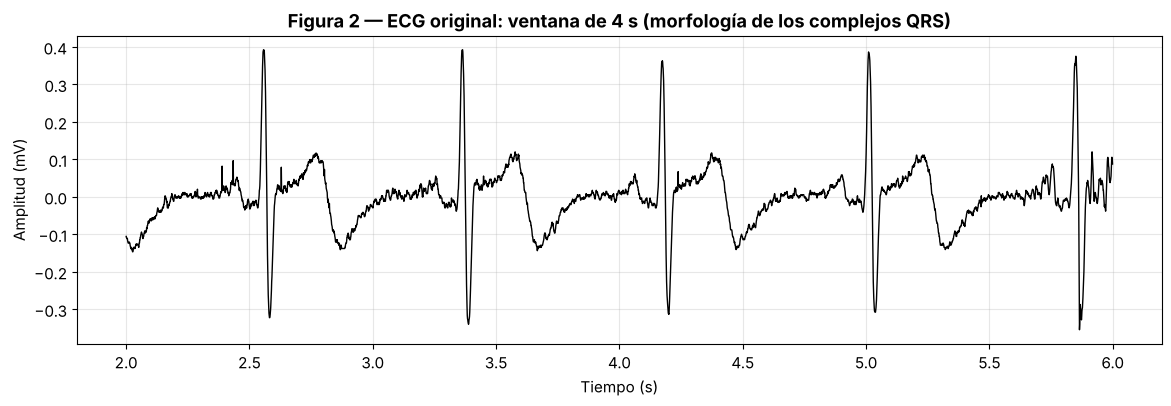

In [8]:
# Ventana de observación para todos los acercamientos (se ajusta si el registro es corto)
DURACION_ZOOM = 4.0                                   # segundos
T_INICIO_ZOOM = 2.0 if duracion_total > 8 else 0.0    # evitamos el inicio del registro
zoom = (t >= T_INICIO_ZOOM) & (t < T_INICIO_ZOOM + DURACION_ZOOM)

# Figura 1: ECG completo
plt.figure(figsize=(14, 4))
plt.plot(t, ecg_original, color="black", lw=0.7)
plt.title("Figura 1 — ECG original completo (canal A2, BITalino/OpenSignals)")
plt.xlabel("Tiempo (s)"); plt.ylabel("Amplitud (mV)")
plt.show()

# Figura 2: ventana corta
plt.figure(figsize=(14, 4))
plt.plot(t[zoom], ecg_original[zoom], color="black", lw=1)
plt.title(f"Figura 2 — ECG original: ventana de {DURACION_ZOOM:.0f} s (morfología de los complejos QRS)")
plt.xlabel("Tiempo (s)"); plt.ylabel("Amplitud (mV)")
plt.show()

### 🔎 Interpretación

- En la **Figura 1** se observa la señal completa: verifica si la línea de base es estable o presenta deriva (*baseline wander*), y si hay artefactos.
- En la **Figura 2** identifica los **complejos QRS** (picos agudos), las ondas **P** y **T**.
- Recuerda: aunque esta señal es **real**, ya trae consigo cierta cantidad de ruido propio de la adquisición. No es una señal "perfecta".

### ❓ Pregunta al estudiante (Bloque 2)

A partir de la Figura 2, estima la frecuencia cardiaca (latidos por minuto) contando los complejos QRS en la ventana.

In [9]:
# Verificación para la pregunta: detección de complejos QRS (solo para contar latidos)
picos, _ = signal.find_peaks(ecg_original, height=0.2, distance=int(0.4 * Fs))   # ≥ 0.2 mV y ≥ 0.4 s entre latidos
t_picos = picos / Fs

en_ventana = t_picos[(t_picos >= T_INICIO_ZOOM) & (t_picos < T_INICIO_ZOOM + DURACION_ZOOM)]
rr_ventana = np.diff(en_ventana)
print(f"QRS en la ventana de {DURACION_ZOOM:.0f} s: {len(en_ventana)} → t = {np.round(en_ventana, 2)} s")
print(f"RR medio en la ventana: {rr_ventana.mean():.3f} s → {60 / rr_ventana.mean():.1f} lpm")

rr_total = np.diff(t_picos)
print(f"Registro completo: {len(picos)} QRS | RR medio {rr_total.mean():.3f} s → {60 / rr_total.mean():.1f} lpm "
      f"(rango {60 / rr_total.max():.0f}–{60 / rr_total.min():.0f} lpm)")

QRS en la ventana de 4 s: 5 → t = [2.56 3.36 4.17 5.01 5.85] s
RR medio en la ventana: 0.823 s → 72.9 lpm
Registro completo: 41 QRS | RR medio 0.852 s → 70.4 lpm (rango 60–85 lpm)


✍️ **Respuesta:**

- En la ventana de 2–6 s hay **5 complejos QRS** (≈ 2.56, 3.36, 4.17, 5.01 y 5.85 s).
- El intervalo RR medio es ≈ 0.82 s, es decir **≈ 73 lpm**. (Contar 5 latidos en 4 s × 15 daría 75 lpm, pero sobrestima porque la ventana empieza y termina justo en un QRS; medir el RR es más preciso.)
- En todo el registro: 41 QRS → ≈ 70 lpm (rango ≈ 60–85 lpm), dentro del rango típico de reposo en adultos (60–100 lpm).

---
# 🟦 BLOQUE 3 — Contaminación artificial de la señal *(20 min)*

## 3.1 ¿Por qué contaminar artificialmente?

Para **evaluar un filtro necesitamos saber cuál es la "respuesta correcta"**. Si contaminamos nosotros mismos la señal con componentes **conocidas**, podemos comparar la señal filtrada con la original y medir qué tan bien se recuperó.

$$ECG_{contaminado} = ECG_{original} + \text{interferencia}_1 + \text{interferencia}_2 + \text{ruido gaussiano}$$

> ⚠️ **Importante:** esta es una **contaminación artificial y controlada con fines didácticos**. Las frecuencias elegidas **no** representan todas las fuentes reales de ruido de un ECG (en la práctica también hay deriva de línea de base, artefactos de movimiento, ruido muscular/EMG, mal contacto de electrodos, etc.).

**Elección de frecuencias:** en Perú la red eléctrica opera a **60 Hz**, por eso usamos $f_1 = 60$ Hz y su segundo armónico $f_2 = 120$ Hz. Si quieres reproducir el caso europeo, cambia a 50 y 100 Hz. **Todos los parámetros son modificables.**

In [10]:
# =================== PARÁMETROS MODIFICABLES ===================
f1 = 60          # Hz — interferencia 1 (red eléctrica en Perú)
f2 = 120         # Hz — interferencia 2 (armónico de la red)

escala = np.std(ecg_original)    # referencia de amplitud de la propia señal
amplitud_1 = 1.0 * escala        # amplitud de la interferencia 1 (mV)
amplitud_2 = 0.6 * escala        # amplitud de la interferencia 2 (mV)
sigma_ruido = 0.3 * escala       # desviación estándar del ruido gaussiano (mV)
# ===============================================================

# Fases aleatorias (pero reproducibles): las interferencias reales no empiezan en fase cero
fase_1, fase_2 = rng.uniform(0, 2 * np.pi, size=2)

ruido_senoidal_1 = amplitud_1 * np.sin(2 * np.pi * f1 * t + fase_1)
ruido_senoidal_2 = amplitud_2 * np.sin(2 * np.pi * f2 * t + fase_2)
ruido_gaussiano = rng.normal(0, sigma_ruido, size=len(t))

ecg_contaminado = (
    ecg_original
    + ruido_senoidal_1
    + ruido_senoidal_2
    + ruido_gaussiano
)

print(f"Interferencia 1: {f1} Hz, amplitud {amplitud_1:.3f} mV")
print(f"Interferencia 2: {f2} Hz, amplitud {amplitud_2:.3f} mV")
print(f"Ruido gaussiano: sigma = {sigma_ruido:.3f} mV")

Interferencia 1: 60 Hz, amplitud 0.080 mV
Interferencia 2: 120 Hz, amplitud 0.048 mV
Ruido gaussiano: sigma = 0.024 mV


## 3.2 Visualización de cada componente

Usamos una ventana de 1 segundo para que las oscilaciones sean distinguibles.

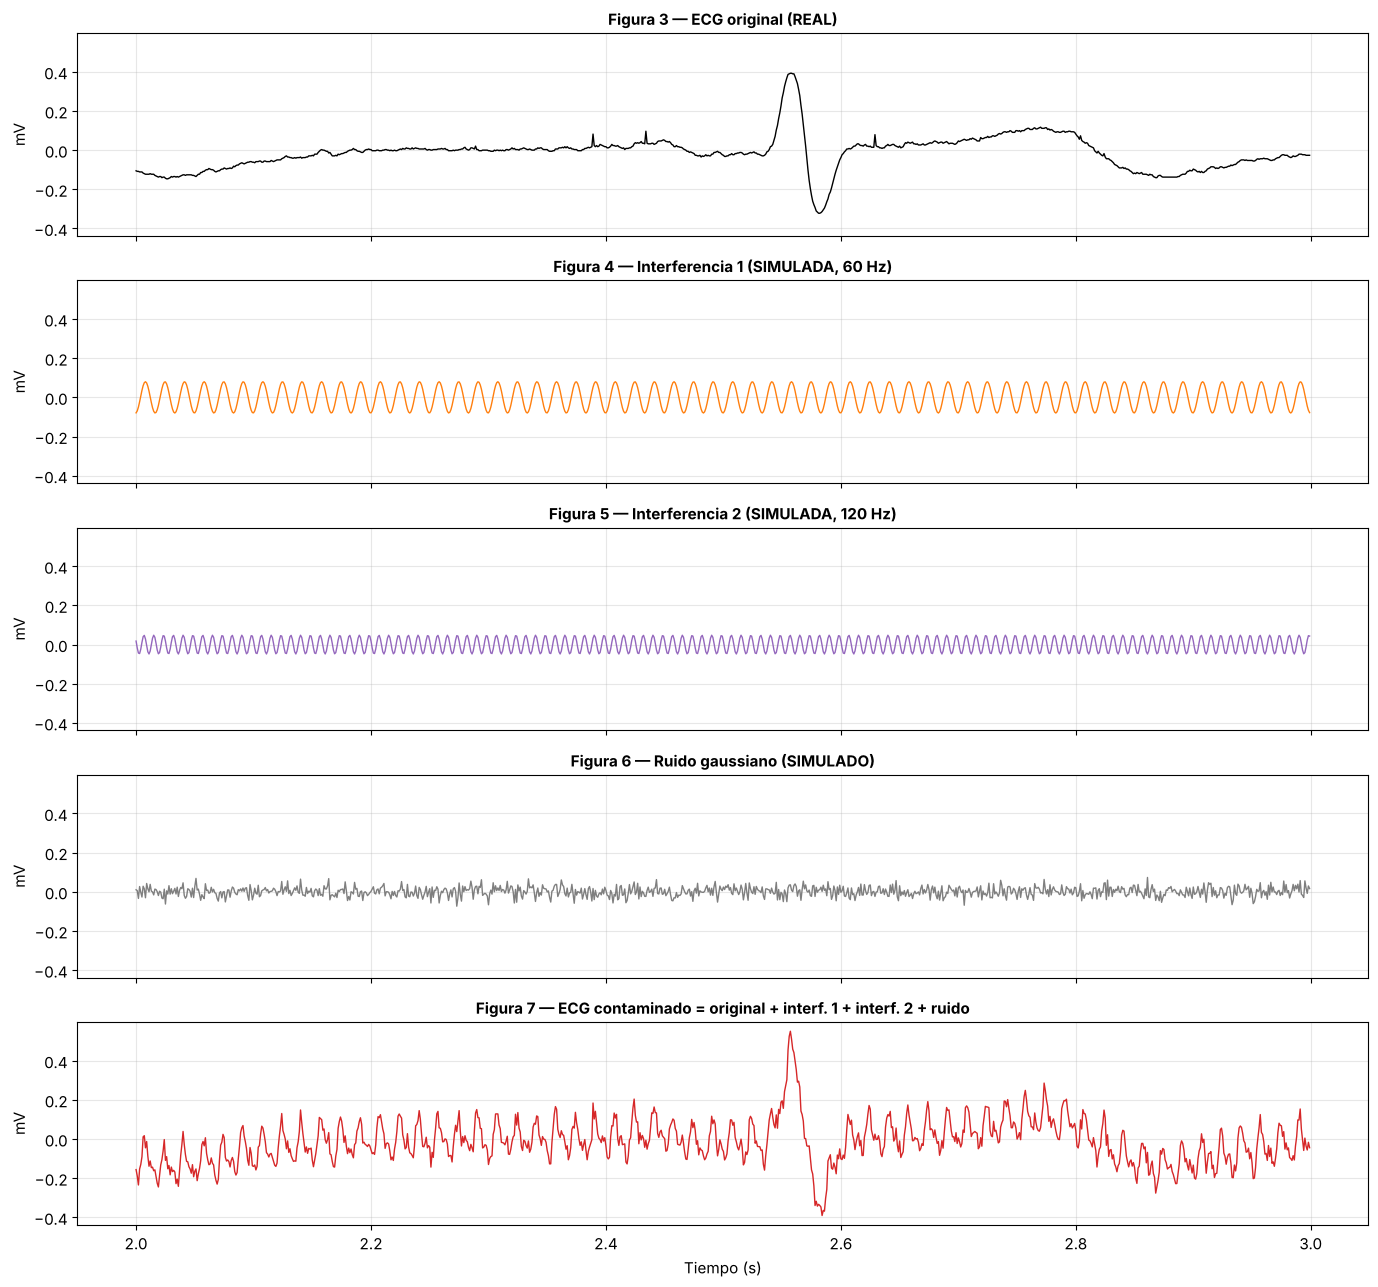

In [11]:
ventana_1s = (t >= T_INICIO_ZOOM) & (t < T_INICIO_ZOOM + 1.0)

componentes = [
    ("Figura 3 — ECG original (REAL)", ecg_original, "black"),
    (f"Figura 4 — Interferencia 1 (SIMULADA, {f1} Hz)", ruido_senoidal_1, "tab:orange"),
    (f"Figura 5 — Interferencia 2 (SIMULADA, {f2} Hz)", ruido_senoidal_2, "tab:purple"),
    ("Figura 6 — Ruido gaussiano (SIMULADO)", ruido_gaussiano, "tab:gray"),
    ("Figura 7 — ECG contaminado = original + interf. 1 + interf. 2 + ruido", ecg_contaminado, "tab:red"),
]

fig, ejes = plt.subplots(len(componentes), 1, figsize=(14, 13), sharex=True, sharey=True)
for eje, (titulo, senal, color) in zip(ejes, componentes):
    eje.plot(t[ventana_1s], senal[ventana_1s], color=color, lw=1)
    eje.set_title(titulo, fontsize=11)
    eje.set_ylabel("mV")
ejes[-1].set_xlabel("Tiempo (s)")
plt.tight_layout(); plt.show()

```
ECG original
      ↓
+ interferencias (f1, f2)
      ↓
+ ruido gaussiano
      ↓
ECG contaminado
```

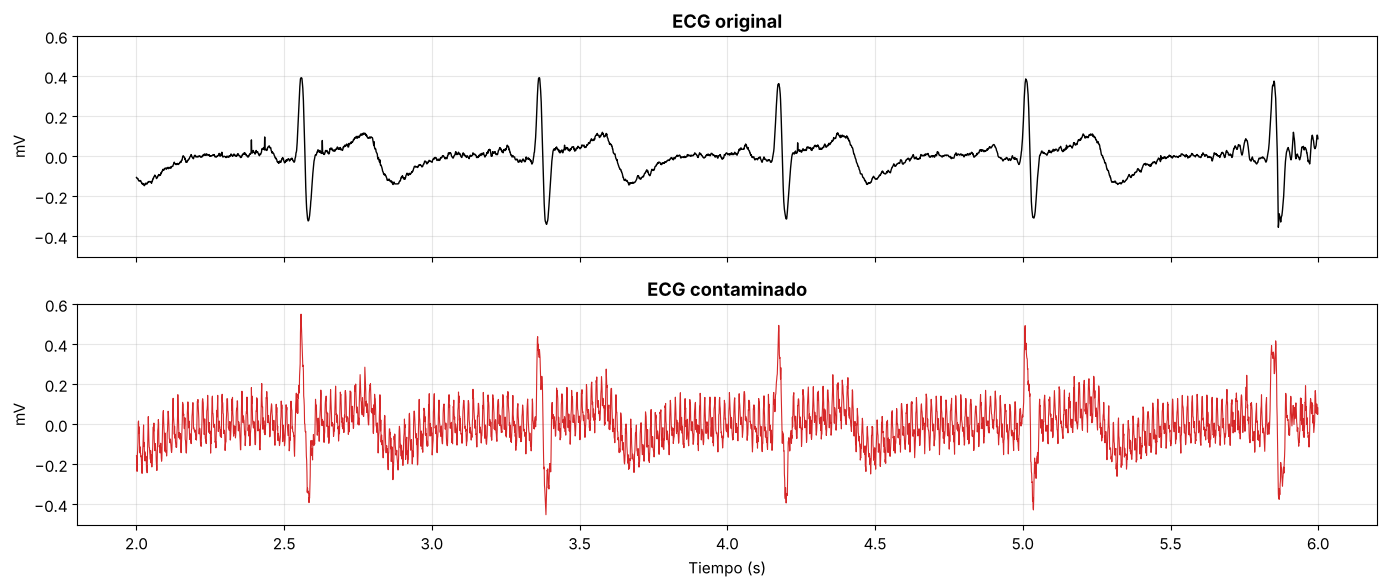

In [12]:
# Comparación directa en la ventana de 4 s
fig, ejes = plt.subplots(2, 1, figsize=(14, 6), sharex=True, sharey=True)
ejes[0].plot(t[zoom], ecg_original[zoom], color="black", lw=1)
ejes[0].set_title("ECG original")
ejes[1].plot(t[zoom], ecg_contaminado[zoom], color="tab:red", lw=0.8)
ejes[1].set_title("ECG contaminado")
for eje in ejes: eje.set_ylabel("mV")
ejes[1].set_xlabel("Tiempo (s)")
plt.tight_layout(); plt.show()

### 🔎 Observa y anota

- ¿Cambió la amplitud aparente de la señal?
- ¿Se conserva la forma de las ondas P y T?
- ¿Qué oscilaciones regulares aparecen?
- ¿Hay ruido de alta frecuencia ("grosor" del trazo)?
- ¿Es más difícil identificar los complejos QRS?

✍️ **Respuesta:**

- **Amplitud aparente:** sí aumenta. El trazo se ve más grueso y con mayor excursión porque las interferencias (0.080 mV a 60 Hz y 0.048 mV a 120 Hz) se suman al ECG.
- **Ondas P y T:** siguen presentes pero quedan **parcialmente enmascaradas**: su amplitud es del orden de 0.1 mV o menos (estimación visual de la Figura 2), comparable a la interferencia de 60 Hz.
- **Oscilaciones regulares:** una oscilación rápida de 60 Hz (60 ciclos por segundo) con otra de 120 Hz superpuesta.
- **Ruido de alta frecuencia:** sí, es el "grosor" del trazo (σ = 0.024 mV).
- **QRS:** siguen siendo identificables (≈ 0.75 mV pico a pico en este registro, muy por encima de la interferencia), pero cuesta más delinearlos con precisión; lo más afectado son las ondas P y T.

## 3.3 Análisis en el dominio de la frecuencia

> Una señal puede analizarse no solamente en función del tiempo, sino también en función de sus **componentes frecuenciales**.

```
Dominio temporal
        ↕  Transformada de Fourier (FFT)
Dominio frecuencial
```

Intuitivamente, la FFT responde: *¿cuánto de cada frecuencia contiene la señal?* Una senoide pura de frecuencia $f_0$ aparece como **un pico estrecho** en $f_0$. El ruido gaussiano, en cambio, reparte su energía en **todas** las frecuencias (fondo plano).

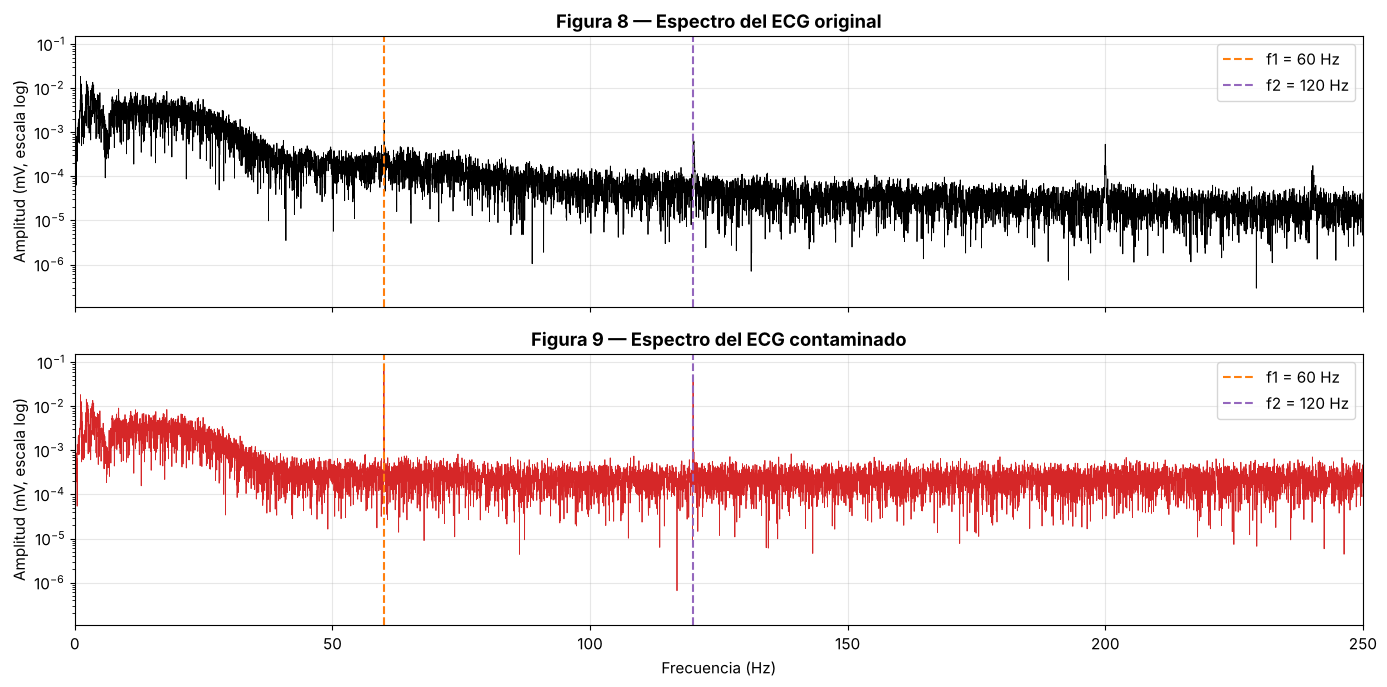

In [13]:
def espectro_amplitud(x, Fs):
    """Espectro de amplitud de un solo lado usando la FFT de NumPy."""
    N = len(x)
    X = np.fft.rfft(x - np.mean(x))
    frecuencias = np.fft.rfftfreq(N, d=1/Fs)
    amplitud = 2 * np.abs(X) / N
    return frecuencias[1:], amplitud[1:]     # omitimos 0 Hz (la media ya fue restada)

freq, amp_original = espectro_amplitud(ecg_original, Fs)
_,    amp_contaminado = espectro_amplitud(ecg_contaminado, Fs)

F_MAX_GRAFICO = min(250, Fs / 2)
fig, ejes = plt.subplots(2, 1, figsize=(14, 7), sharex=True, sharey=True)
ejes[0].semilogy(freq, amp_original, color="black", lw=0.6)
ejes[0].set_title("Figura 8 — Espectro del ECG original")
ejes[1].semilogy(freq, amp_contaminado, color="tab:red", lw=0.6)
ejes[1].set_title("Figura 9 — Espectro del ECG contaminado")
for eje in ejes:
    eje.axvline(f1, color="tab:orange", ls="--", label=f"f1 = {f1} Hz")
    eje.axvline(f2, color="tab:purple", ls="--", label=f"f2 = {f2} Hz")
    eje.set_ylabel("Amplitud (mV, escala log)")
    eje.legend(loc="upper right")
ejes[1].set_xlabel("Frecuencia (Hz)")
ejes[1].set_xlim(0, F_MAX_GRAFICO)
plt.tight_layout(); plt.show()

### 🔎 Interpretación

- El ECG concentra la mayor parte de su energía en **bajas frecuencias** (aprox. < 40 Hz).
- En el espectro contaminado aparecen **dos picos nítidos** exactamente en $f_1$ y $f_2$: son las interferencias que **nosotros** introdujimos.
- El ruido gaussiano **eleva el "piso"** del espectro en todas las frecuencias.
- Si en el ECG original ya aparece algún pico en 60 Hz, ¡esa sería interferencia **real** de la adquisición!

### ❓ Pregunta al estudiante

¿Por qué la interferencia aparece como un pico y el ruido gaussiano como un fondo? ¿Cuál de los dos será más fácil de eliminar con un filtro?

In [14]:
# Verificación: ¿hay un pico real de 60 Hz en el ECG original?
fr_o, am_o = espectro_amplitud(ecg_original, Fs)
i60 = np.argmin(np.abs(fr_o - 60))
vecinos = np.r_[am_o[i60 - 30:i60 - 3], am_o[i60 + 3:i60 + 30]]
print(f"ECG original — amplitud en 60 Hz: {am_o[i60]:.2e} mV | mediana de los vecinos: {np.median(vecinos):.2e} mV "
      f"| cociente: {am_o[i60] / np.median(vecinos):.1f}")
print(f"Interferencia simulada a 60 Hz: {amplitud_1:.3f} mV")

ECG original — amplitud en 60 Hz: 9.56e-04 mV | mediana de los vecinos: 2.31e-04 mV | cociente: 4.1
Interferencia simulada a 60 Hz: 0.080 mV


✍️ **Respuesta:**

- **Pico vs fondo:** una interferencia de red es una senoide, con toda su energía en **una sola frecuencia** (60 y 120 Hz), por eso aparece como un pico estrecho. El ruido gaussiano es aleatorio y reparte su potencia en **todas** las frecuencias, así que forma un piso plano.
- **Más fácil de eliminar:** la **interferencia**. Al ser de banda estrecha y frecuencia conocida, un notch (o el LMS) la quita sin tocar casi nada más. El ruido gaussiano ocupa también la banda del ECG (0.5–40 Hz), así que ningún filtro lineal puede separarlo por completo: solo se recorta la parte que cae fuera de esa banda.
- En el ECG original sí hay un pequeño pico real en 60 Hz (ver la celda anterior), pero es despreciable frente a los 0.08 mV de la interferencia simulada.

---
# 🟦 BLOQUE 4 — Aplicación de filtros digitales *(25 min)*

## 4.1 Tipos de filtros

| Filtro | Deja pasar | Uso típico en ECG |
|---|---|---|
| **Pasa-bajas** | Frecuencias por debajo de $f_c$ | Atenuar ruido de alta frecuencia (EMG, ruido electrónico). |
| **Pasa-altas** | Frecuencias por encima de $f_c$ | Eliminar la deriva de línea de base (respiración, movimiento). |
| **Pasa-banda** | Frecuencias entre $f_{c1}$ y $f_{c2}$ | Combinar ambos: típico 0.5 – 40 Hz para monitoreo. |
| **Notch (rechaza-banda)** | Todo excepto una banda muy estrecha | Eliminar una interferencia de frecuencia conocida (red eléctrica). |

**Herramientas de `scipy.signal`:**

- `butter`: diseña un filtro Butterworth (respuesta plana en la banda de paso).
- `iirnotch`: diseña un filtro notch centrado en una frecuencia.
- `filtfilt`: aplica el filtro hacia adelante y hacia atrás → **fase cero** (no desplaza los QRS en el tiempo).
- `freqz`: calcula la respuesta en frecuencia del filtro.

> 💡 Para el pasa-banda usamos la forma **SOS** (*second-order sections*) con `sosfiltfilt`, que es el equivalente numéricamente estable de `filtfilt` cuando la frecuencia de corte es muy baja respecto a $F_s$ (0.5 Hz frente a 1000 Hz).

In [15]:
def respuesta_sos(sos, Fs, n_puntos=16384):
    """Respuesta en frecuencia de un filtro en formato SOS (compatible con varias versiones de SciPy)."""
    funcion = getattr(signal, "freqz_sos", None) or signal.sosfreqz
    return funcion(sos, worN=n_puntos, fs=Fs)

def graficar_respuesta(w, h, titulo, marcas=()):
    plt.figure(figsize=(14, 3.5))
    plt.plot(w, 20 * np.log10(np.maximum(np.abs(h), 1e-10)), color="tab:blue")
    for f in marcas:
        plt.axvline(f, color="tab:red", ls="--", lw=1)
    plt.ylim(-80, 5); plt.xlim(0, F_MAX_GRAFICO)
    plt.title(titulo); plt.xlabel("Frecuencia (Hz)"); plt.ylabel("Ganancia (dB)")
    plt.show()

## 4.2 Experimento A — Filtro pasa-banda (Butterworth 0.5 – 40 Hz)

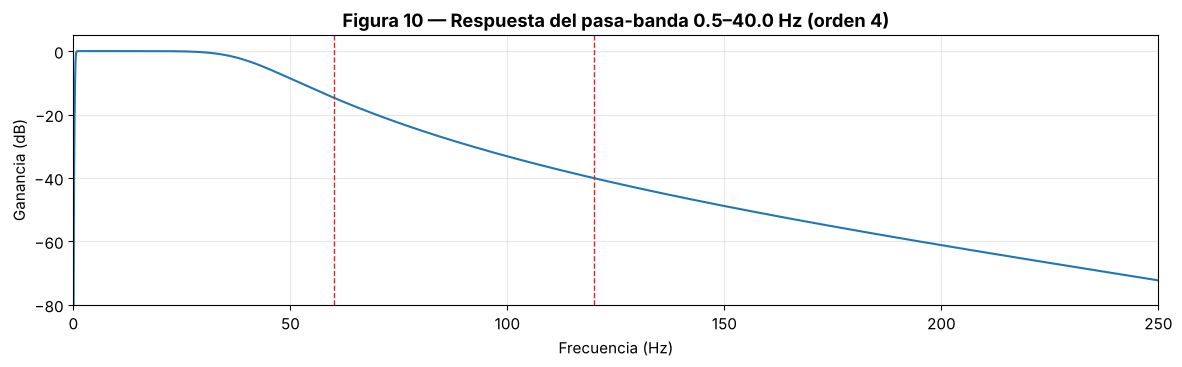

In [16]:
# =================== PARÁMETROS MODIFICABLES ===================
fc_baja = 0.5     # Hz
fc_alta = 40.0    # Hz
orden_pb = 4
# ===============================================================

sos_pasabanda = signal.butter(orden_pb, [fc_baja, fc_alta], btype="bandpass", fs=Fs, output="sos")
ecg_pasabanda = signal.sosfiltfilt(sos_pasabanda, ecg_contaminado)

w, h = respuesta_sos(sos_pasabanda, Fs)
graficar_respuesta(w, h, f"Figura 10 — Respuesta del pasa-banda {fc_baja}–{fc_alta} Hz (orden {orden_pb})", marcas=(f1, f2))

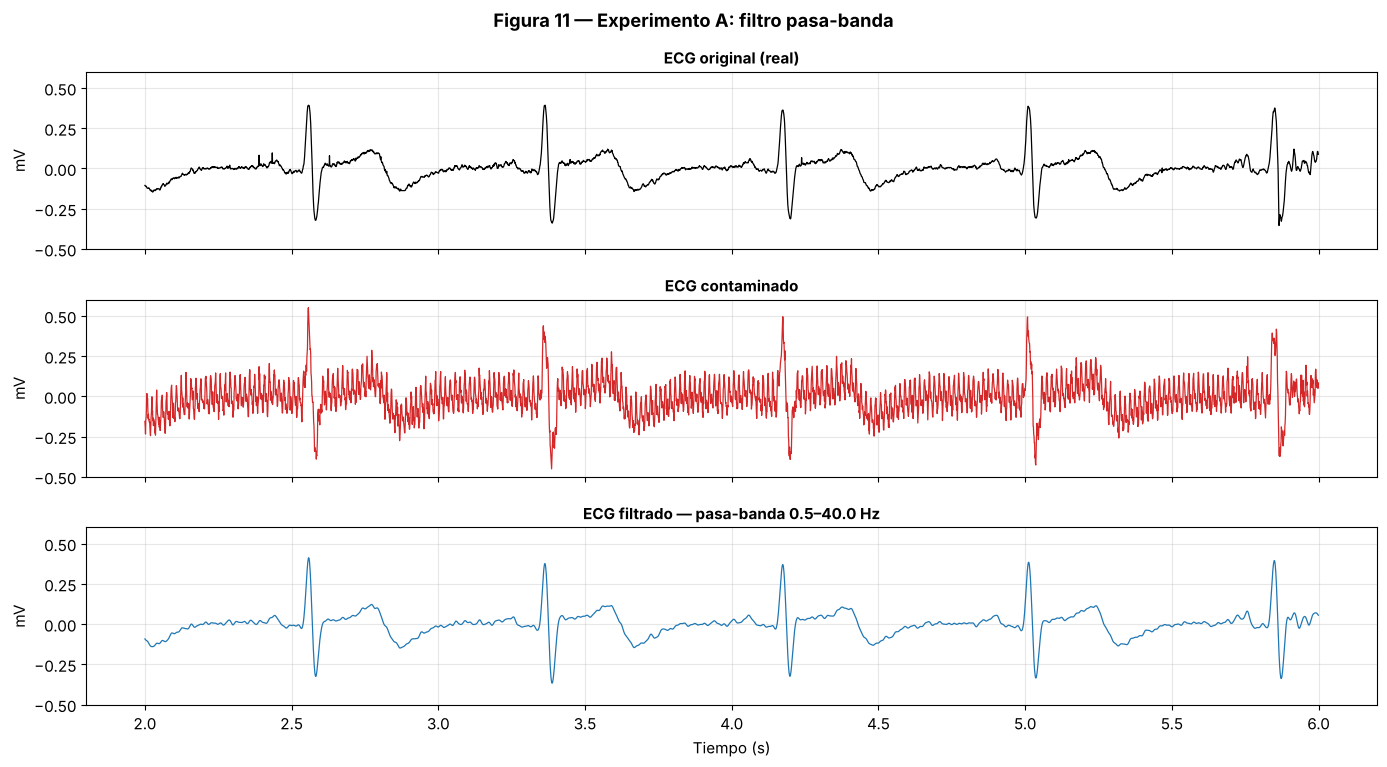

In [17]:
def comparar_senales(lista, titulo_general, mascara=zoom):
    """Grafica varias señales (titulo, señal, color) apiladas en la misma ventana temporal."""
    fig, ejes = plt.subplots(len(lista), 1, figsize=(14, 2.6 * len(lista)), sharex=True, sharey=True)
    for eje, (titulo, senal, color) in zip(ejes, lista):
        eje.plot(t[mascara], senal[mascara], color=color, lw=0.9)
        eje.set_title(titulo, fontsize=11); eje.set_ylabel("mV")
    ejes[-1].set_xlabel("Tiempo (s)")
    fig.suptitle(titulo_general, fontweight="bold")
    plt.tight_layout(); plt.show()

comparar_senales([
    ("ECG original (real)", ecg_original, "black"),
    ("ECG contaminado", ecg_contaminado, "tab:red"),
    (f"ECG filtrado — pasa-banda {fc_baja}–{fc_alta} Hz", ecg_pasabanda, "tab:blue"),
], "Figura 11 — Experimento A: filtro pasa-banda")

### 🔎 Interpretación — Experimento A

- **¿Qué se eliminó?** Ambas interferencias ($f_1$ y $f_2$ están fuera de la banda de paso) y la mayor parte del ruido gaussiano de alta frecuencia.
- **¿Qué permanece?** El ruido gaussiano que cae **dentro** de 0.5 – 40 Hz: ningún filtro lineal puede separarlo del ECG porque comparten frecuencias.
- **¿Qué se pudo afectar?** El pasa-banda también elimina contenido **real** del ECG: la deriva de línea de base (< 0.5 Hz) y parte del contenido de alta frecuencia del QRS (> 40 Hz). Observa si los picos R se ven un poco más bajos o redondeados.

## 4.3 Experimento B — Filtro notch

El notch elimina **una frecuencia concreta** y deja prácticamente intacto el resto del espectro. El **factor de calidad** $Q$ controla el ancho de la muesca: $\text{ancho} \approx f_0/Q$.

**B1:** notch solo en $f_1$. **B2:** dos notch en cascada ($f_1$ y $f_2$).

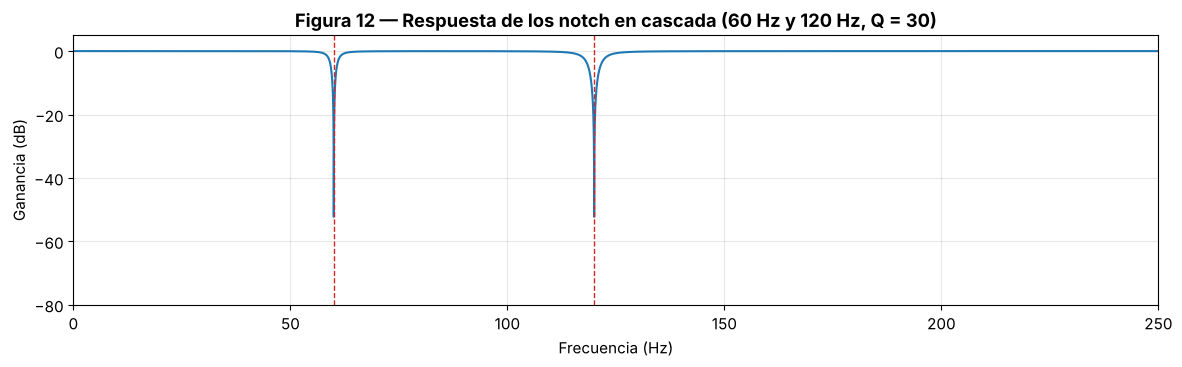

In [18]:
Q = 30   # factor de calidad (mayor Q → muesca más estrecha)

b_notch1, a_notch1 = signal.iirnotch(f1, Q, fs=Fs)
b_notch2, a_notch2 = signal.iirnotch(f2, Q, fs=Fs)

# B1: solo f1
ecg_notch_f1 = signal.filtfilt(b_notch1, a_notch1, ecg_contaminado)
# B2: f1 y luego f2 (cascada)
ecg_notch_f1f2 = signal.filtfilt(b_notch2, a_notch2, ecg_notch_f1)

# Respuesta en frecuencia de la cascada (producto de ambas respuestas)
w, h1 = signal.freqz(b_notch1, a_notch1, worN=16384, fs=Fs)
_, h2 = signal.freqz(b_notch2, a_notch2, worN=16384, fs=Fs)
graficar_respuesta(w, h1 * h2, f"Figura 12 — Respuesta de los notch en cascada ({f1} Hz y {f2} Hz, Q = {Q})", marcas=(f1, f2))

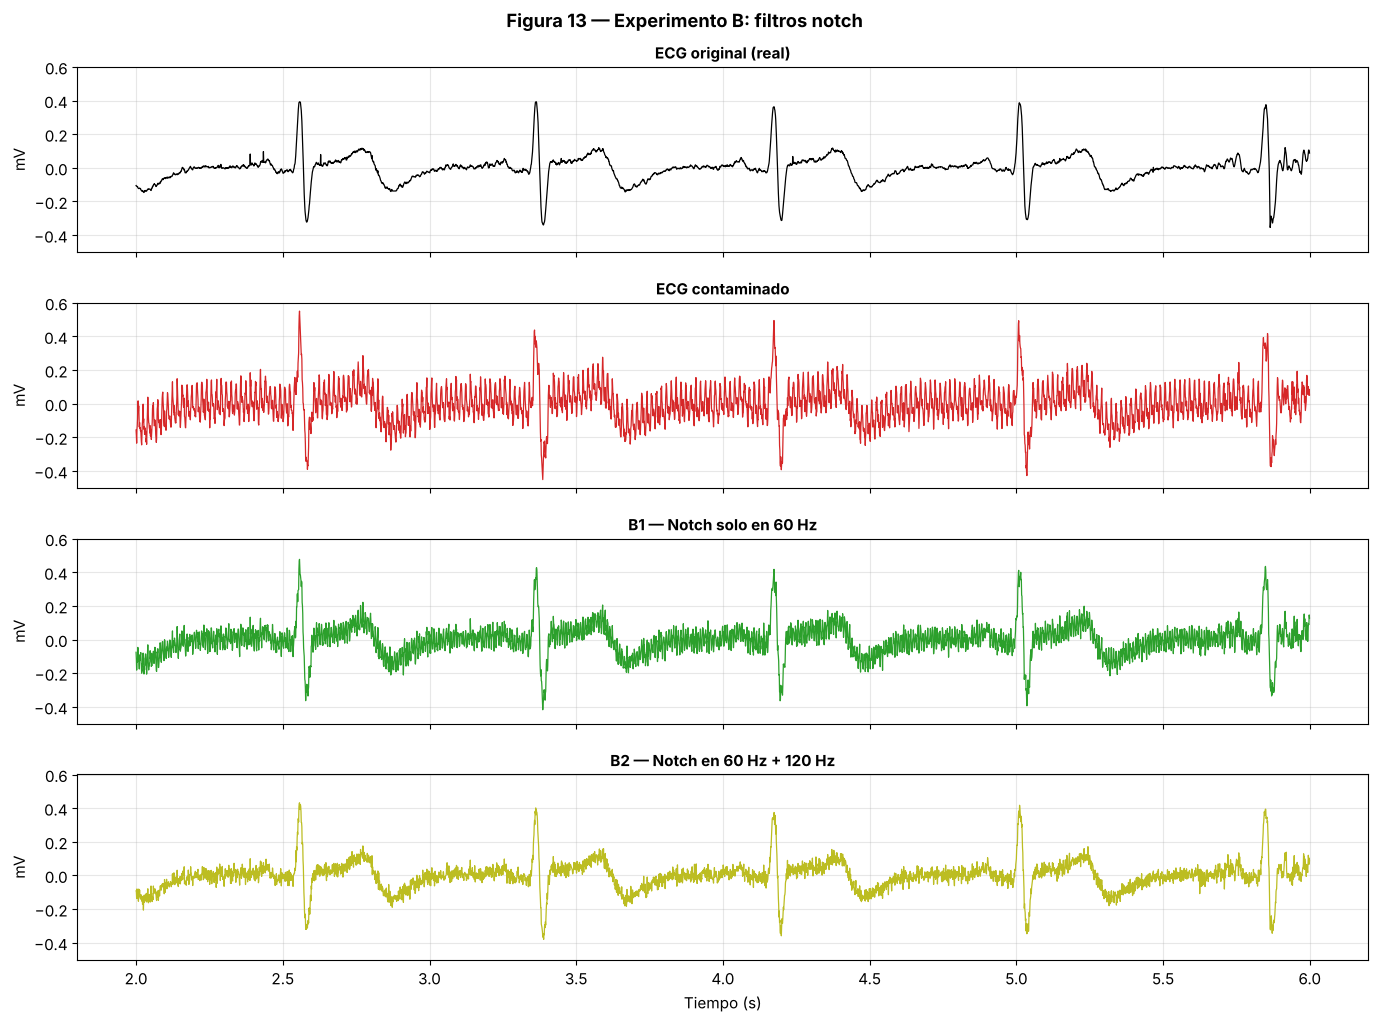

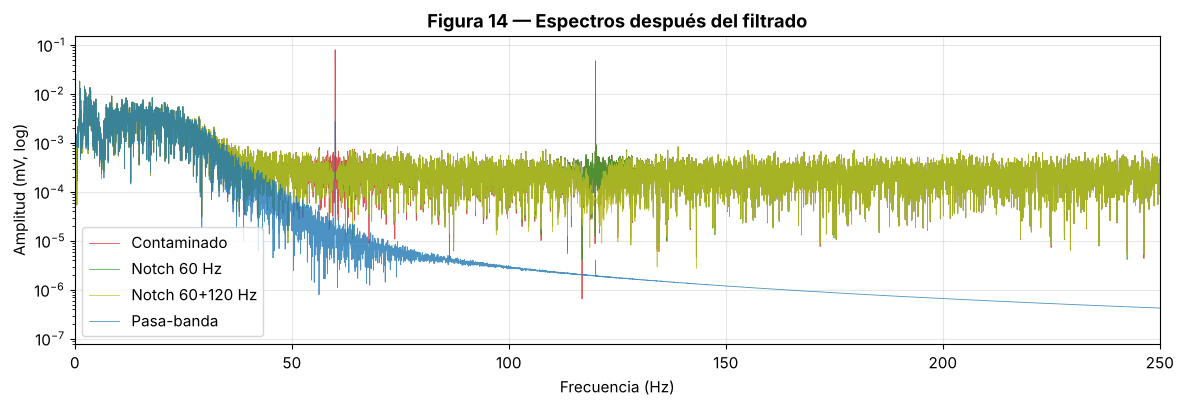

In [19]:
comparar_senales([
    ("ECG original (real)", ecg_original, "black"),
    ("ECG contaminado", ecg_contaminado, "tab:red"),
    (f"B1 — Notch solo en {f1} Hz", ecg_notch_f1, "tab:green"),
    (f"B2 — Notch en {f1} Hz + {f2} Hz", ecg_notch_f1f2, "tab:olive"),
], "Figura 13 — Experimento B: filtros notch")

# Espectros después de cada filtrado
fig, eje = plt.subplots(figsize=(14, 4))
for etiqueta, senal, color in [("Contaminado", ecg_contaminado, "tab:red"),
                               (f"Notch {f1} Hz", ecg_notch_f1, "tab:green"),
                               (f"Notch {f1}+{f2} Hz", ecg_notch_f1f2, "tab:olive"),
                               ("Pasa-banda", ecg_pasabanda, "tab:blue")]:
    fr, am = espectro_amplitud(senal, Fs)
    eje.semilogy(fr, am, lw=0.6, label=etiqueta, color=color, alpha=0.8)
eje.set_xlim(0, F_MAX_GRAFICO); eje.legend()
eje.set_title("Figura 14 — Espectros después del filtrado")
eje.set_xlabel("Frecuencia (Hz)"); eje.set_ylabel("Amplitud (mV, log)")
plt.show()

### 🔎 Interpretación — Experimento B

- **B1** elimina el pico en $f_1$, pero el de $f_2$ **sigue ahí**: el notch solo actúa donde se lo indicamos.
- **B2** elimina ambos picos, pero el **ruido gaussiano permanece** (el notch no reduce el ruido de banda ancha).
- **Ventaja:** el notch altera muy poco la morfología del ECG porque solo "corta" una banda estrecha.
- **Limitación:** exige conocer la frecuencia exacta y que esta **no cambie** en el tiempo.

### ❓ Pregunta al estudiante

Cambia `Q` a 5 y luego a 100. ¿Qué ocurre con el ancho de la muesca (Figura 12) y con la señal filtrada?

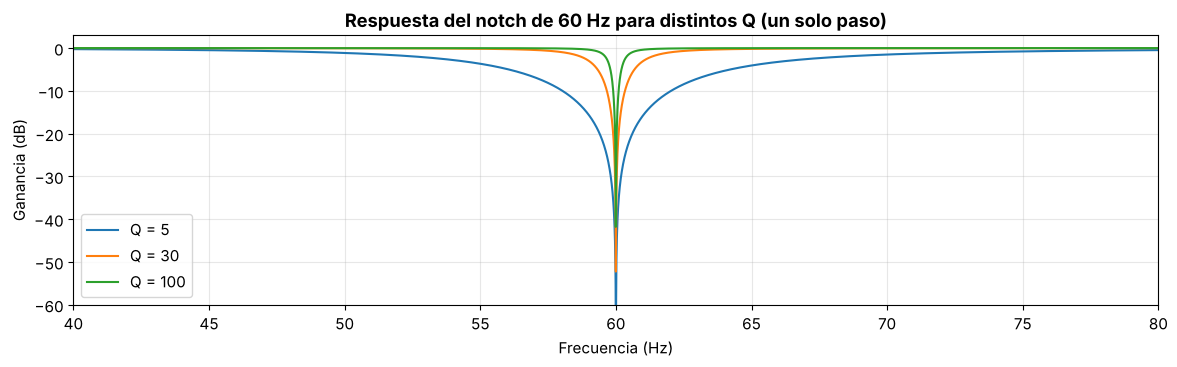

,Ancho a -3 dB (Hz),Ancho teórico f1/Q (Hz),SNR contaminado→filtrado (dB),RMSE (mV),Residuo a 60 Hz (µV),SNR notch aplicado al ORIGINAL (dB)
Q = 5,11.9934,12.0,10.9296,0.0225,0.0764,26.3155
Q = 30,1.9913,2.0,10.4038,0.0239,0.2460,29.2963
Q = 100,0.5875,0.6,10.3355,0.0241,0.6788,30.4516


In [20]:
# Verificación: efecto de Q (5, 30, 100) sobre el notch de f1 y de f2 en cascada
def snr_rmse(referencia, estimada, margen=2.0):
    """SNR (dB) y RMSE (mV) excluyendo `margen` s en cada extremo (las métricas formales se definen en la sección 4.4)."""
    m = (t >= margen) & (t <= t[-1] - margen)
    err = estimada[m] - referencia[m]
    return 10 * np.log10(np.sum(referencia[m] ** 2) / np.sum(err ** 2)), np.sqrt(np.mean(err ** 2))

fig, eje = plt.subplots(figsize=(14, 3.5))
filas = {}
for Qx in (5, 30, 100):
    b1, a1 = signal.iirnotch(f1, Qx, fs=Fs)
    b2, a2 = signal.iirnotch(f2, Qx, fs=Fs)
    w_, h_ = signal.freqz(b1, a1, worN=65536, fs=Fs)
    eje.plot(w_, 20 * np.log10(np.maximum(np.abs(h_), 1e-10)), label=f"Q = {Qx}")
    cerca = (np.abs(w_ - f1) < 40) & (np.abs(h_) < 1 / np.sqrt(2))      # banda a -3 dB (un solo paso)
    ancho = w_[cerca].max() - w_[cerca].min()

    filtrada = signal.filtfilt(b2, a2, signal.filtfilt(b1, a1, ecg_contaminado))
    sobre_original = signal.filtfilt(b2, a2, signal.filtfilt(b1, a1, ecg_original))
    fr_f, am_f = espectro_amplitud(filtrada, Fs)
    snr_c, rmse_c = snr_rmse(ecg_original, filtrada)
    snr_o, _ = snr_rmse(ecg_original, sobre_original)
    filas[f"Q = {Qx}"] = {
        "Ancho a -3 dB (Hz)": ancho,
        "Ancho teórico f1/Q (Hz)": f1 / Qx,
        "SNR contaminado→filtrado (dB)": snr_c,
        "RMSE (mV)": rmse_c,
        "Residuo a 60 Hz (µV)": 1000 * am_f[np.argmin(np.abs(fr_f - f1))],
        "SNR notch aplicado al ORIGINAL (dB)": snr_o,
    }
eje.set_xlim(40, 80); eje.set_ylim(-60, 3); eje.legend()
eje.set_title("Respuesta del notch de 60 Hz para distintos Q (un solo paso)")
eje.set_xlabel("Frecuencia (Hz)"); eje.set_ylabel("Ganancia (dB)")
plt.show()
pd.DataFrame(filas).T.round(4)

✍️ **Respuesta:**

- **Ancho de la muesca:** se ensancha al bajar Q: ≈ 12 Hz con Q = 5, ≈ 2 Hz con Q = 30 y ≈ 0.6 Hz con Q = 100, tal como predice $\text{ancho} \approx f_0/Q$.
- **Q = 5 (muesca ancha):** quita la interferencia y también parte del ECG vecino a 60 Hz: aplicado al ECG original da SNR 26.3 dB frente a 29.3 dB (Q = 30) y 30.5 dB (Q = 100), o sea, **más distorsión**. Tolera pequeñas variaciones de la frecuencia de red.
- **Q = 100 (muesca estrecha):** casi no altera el ECG, pero en este registro deja **más residuo a 60 Hz** (≈ 0.68 µV frente a ≈ 0.08 µV con Q = 5) y solo es adecuado si la red se mantiene exactamente en 60 Hz.
- El SNR global casi no cambia (10.9, 10.4 y 10.3 dB) porque el error lo domina el ruido gaussiano (RMSE ≈ σ = 0.024 mV), que el notch no toca. Q = 30 es un buen compromiso.

## 4.4 Comparación cuantitativa

Las métricas **complementan** (no reemplazan) la evaluación visual:

| Métrica | Fórmula | Interpretación |
|---|---|---|
| **RMSE** | $\sqrt{\frac{1}{N}\sum (x-\hat{x})^2}$ | Error promedio (mV). **Menor** es mejor. |
| **SNR** | $10\log_{10}\frac{\sum x^2}{\sum (x-\hat{x})^2}$ | Relación señal/error en dB. **Mayor** es mejor. |
| **Correlación** $r$ | coeficiente de Pearson | Similitud de forma (1 = idéntica). |

donde $x$ es el ECG original y $\hat{x}$ la señal evaluada. Excluimos los primeros y últimos 2 s para evitar efectos de borde (y el tiempo de convergencia del filtro adaptativo que veremos luego).

In [21]:
MARGEN_S = 2.0
evaluacion = (t >= MARGEN_S) & (t <= t[-1] - MARGEN_S)

def calcular_metricas(referencia, estimada, mascara=evaluacion):
    x, y = referencia[mascara], estimada[mascara]
    error = y - x
    rmse = np.sqrt(np.mean(error ** 2))
    snr = 10 * np.log10(np.sum(x ** 2) / np.sum(error ** 2))
    r = np.corrcoef(x, y)[0, 1]
    return {"RMSE (mV)": rmse, "SNR (dB)": snr, "Correlación r": r}

resultados = {
    "Contaminado (sin filtrar)": calcular_metricas(ecg_original, ecg_contaminado),
    "A — Pasa-banda": calcular_metricas(ecg_original, ecg_pasabanda),
    f"B1 — Notch {f1} Hz": calcular_metricas(ecg_original, ecg_notch_f1),
    f"B2 — Notch {f1}+{f2} Hz": calcular_metricas(ecg_original, ecg_notch_f1f2),
}
pd.DataFrame(resultados).T.round(4)

,RMSE (mV),SNR (dB),Correlación r
Contaminado (sin filtrar),0.0699,1.0894,0.7509
A — Pasa-banda,0.0092,18.7216,0.9933
B1 — Notch 60 Hz,0.0414,5.6416,0.8859
B2 — Notch 60+120 Hz,0.0239,10.4038,0.9572


### ¿Cuánto modifica el filtro a la propia señal original?

Un detalle importante: el pasa-banda **también cambia el ECG original** (quita su deriva de base y su contenido > 40 Hz). Para separar "ruido no eliminado" de "distorsión del filtro", filtramos el **original limpio** y lo comparamos consigo mismo.

In [22]:
ecg_original_pasabanda = signal.sosfiltfilt(sos_pasabanda, ecg_original)
ecg_original_notch = signal.filtfilt(b_notch2, a_notch2, signal.filtfilt(b_notch1, a_notch1, ecg_original))

pd.DataFrame({
    "Pasa-banda aplicado al ORIGINAL": calcular_metricas(ecg_original, ecg_original_pasabanda),
    "Notch f1+f2 aplicado al ORIGINAL": calcular_metricas(ecg_original, ecg_original_notch),
}).T.round(4)

,RMSE (mV),SNR (dB),Correlación r
Pasa-banda aplicado al ORIGINAL,0.0065,21.7040,0.9966
Notch f1+f2 aplicado al ORIGINAL,0.0027,29.2963,0.9994


### 🔎 Interpretación

- Si el pasa-banda aplicado al original ya produce un error apreciable, parte del "error" del Experimento A **no es ruido residual**, sino **distorsión introducida por el filtro** (pérdida de deriva de base y de componentes rápidas del QRS).
- El notch casi no modifica el original → distorsión mínima, pero tampoco reduce el ruido gaussiano.
- **Conclusión:** ninguna métrica aislada cuenta toda la historia.

### ❓ Pregunta al estudiante

¿Qué filtro obtuvo mejor SNR? ¿Coincide con lo que observaste visualmente? Explica cualquier diferencia.

In [23]:
# Verificación: ¿por qué el pasa-banda obtiene mejor SNR aunque el ruido gaussiano sea de banda ancha?
fraccion_en_banda = (fc_alta - fc_baja) / (Fs / 2)          # fracción de la potencia de un ruido blanco que cae en 0.5–40 Hz
rms_ruido_en_banda = sigma_ruido * np.sqrt(fraccion_en_banda)
rmse_distorsion = calcular_metricas(ecg_original, ecg_original_pasabanda)["RMSE (mV)"]

print(f"Fracción del ruido gaussiano dentro de {fc_baja}–{fc_alta} Hz: {fraccion_en_banda:.3f}  (≈ {100 * fraccion_en_banda:.1f} %)")
print(f"RMS del ruido que NO se puede quitar (en banda): {rms_ruido_en_banda:.4f} mV")
print(f"RMSE por distorsión propia del pasa-banda (sobre el original): {rmse_distorsion:.4f} mV")
print(f"Suma cuadrática de ambos: {np.hypot(rms_ruido_en_banda, rmse_distorsion):.4f} mV "
      f"(RMSE medido del Experimento A: {resultados['A — Pasa-banda']['RMSE (mV)']:.4f} mV)")

Fracción del ruido gaussiano dentro de 0.5–40.0 Hz: 0.079  (≈ 7.9 %)
RMS del ruido que NO se puede quitar (en banda): 0.0067 mV
RMSE por distorsión propia del pasa-banda (sobre el original): 0.0065 mV
Suma cuadrática de ambos: 0.0094 mV (RMSE medido del Experimento A: 0.0092 mV)


✍️ **Respuesta:**

- **Mejor SNR:** el **pasa-banda 0.5–40 Hz**, con 18.72 dB (RMSE 0.0092 mV, r = 0.9933). Le siguen el híbrido (12.21 dB), el notch 60+120 Hz (10.40 dB), el LMS (10.23 dB), la Wavelet sola (7.56 dB) y el notch solo de 60 Hz (5.64 dB).
- **¿Coincide con lo visual?** En parte. En las Figuras 11 y 18 el pasa-banda también se ve limpio, pero el notch y el LMS conservan mejor la forma del ECG (r ≈ 0.999 el notch sobre el original) y dejan el trazo "grueso" por el ruido gaussiano, que no tocan.
- **Por qué el pasa-banda gana en SNR:** el ruido gaussiano es de banda ancha y solo ≈ 7.9 % de su potencia cae dentro de 0.5–40 Hz, así que el pasa-banda elimina el resto (RMS residual ≈ 0.0067 mV). El notch y el LMS dejan todo ese ruido.
- **Distorsión propia:** el pasa-banda aplicado al ECG original ya da RMSE = 0.0065 mV (SNR 21.7 dB); sumado en cuadratura al ruido residual en banda (≈ 0.0067 mV) da ≈ 0.0094 mV, que explica casi todo el RMSE medido (0.0092 mV). El notch distorsiona mucho menos (SNR 29.3 dB sobre el original).
- **Matiz:** la referencia "original" ya incluye su propio ruido de adquisición, de modo que el SNR también castiga lo que el filtro quita de ese ruido. Por eso una métrica sola no basta.

---
# 🟦 BLOQUE 5 — Filtros adaptativos y Transformada Wavelet *(20 min)*

## 5.1 ¿Qué es un filtro adaptativo?

Un filtro convencional tiene **coeficientes fijos**: se diseña una vez y se aplica igual a toda la señal. Un **filtro adaptativo** modifica sus coeficientes **muestra a muestra** en función de la información que recibe, por lo que puede seguir interferencias cuya amplitud o fase cambian en el tiempo.

```
Señal contaminada d[n] ──────────────────────────►(+)──► e[n] = ECG estimado
                                                    ▲(−)
                                                    │
señal de referencia x[n] ──► Filtro adaptativo ──► y[n] = interferencia estimada
                                  ▲
                                  └──── se ajusta usando el error e[n]
```

| Concepto | Significado en este laboratorio |
|---|---|
| **Señal de referencia** $x[n]$ | Señal correlacionada con la interferencia pero **no** con el ECG (aquí: senos y cosenos de $f_1$ y $f_2$). En la práctica puede provenir de un sensor que capta la interferencia. |
| **Coeficientes** $\mathbf{w}$ | Pesos que el filtro ajusta para "imitar" la interferencia. |
| **Salida** $y[n] = \mathbf{w}^T x[n]$ | Estimación de la interferencia. |
| **Error** $e[n] = d[n] - y[n]$ | Lo que queda al restar la interferencia estimada: **es nuestro ECG limpio**. |
| **Adaptación (LMS)** $\mathbf{w}[n+1] = \mathbf{w}[n] + 2\mu\, e[n]\, x[n]$ | |
| **Paso** $\mu$ | Velocidad de aprendizaje: grande → rápido pero inestable/distorsionante; pequeño → lento pero preciso. |

El algoritmo **LMS** (*Least Mean Squares*) minimiza poco a poco la potencia del error. Como el ECG no está correlacionado con la referencia, la única forma de reducir el error es **cancelar la interferencia**.

In [24]:
def filtro_lms(senal_contaminada, referencias, mu):
    """
    Cancelador adaptativo de interferencias con algoritmo LMS (versión didáctica).

    senal_contaminada : vector d[n] de tamaño N
    referencias       : matriz N x M (cada columna es una señal de referencia)
    mu                : paso de adaptación

    Devuelve: e (señal limpia estimada), y (interferencia estimada), historial de pesos
    """
    N, M = referencias.shape
    w = np.zeros(M)                 # los coeficientes empiezan en cero: el filtro "no sabe nada"
    y = np.zeros(N)
    e = np.zeros(N)
    historial_w = np.zeros((N, M))

    for n in range(N):
        x_n = referencias[n]                 # vector de referencia en el instante n
        y[n] = w @ x_n                       # 1) estimar la interferencia
        e[n] = senal_contaminada[n] - y[n]   # 2) calcular el error (ECG estimado)
        w = w + 2 * mu * e[n] * x_n          # 3) actualizar los coeficientes (LMS)
        historial_w[n] = w
    return e, y, historial_w

# Referencias: seno y coseno de cada frecuencia (permiten ajustar amplitud Y fase)
referencias = np.column_stack([
    np.sin(2 * np.pi * f1 * t), np.cos(2 * np.pi * f1 * t),
    np.sin(2 * np.pi * f2 * t), np.cos(2 * np.pi * f2 * t),
])

MU = 0.005   # =================== PARÁMETRO MODIFICABLE ===================

ecg_lms, interferencia_estimada, pesos = filtro_lms(ecg_contaminado, referencias, MU)
print("Filtrado adaptativo completado.")

Filtrado adaptativo completado.


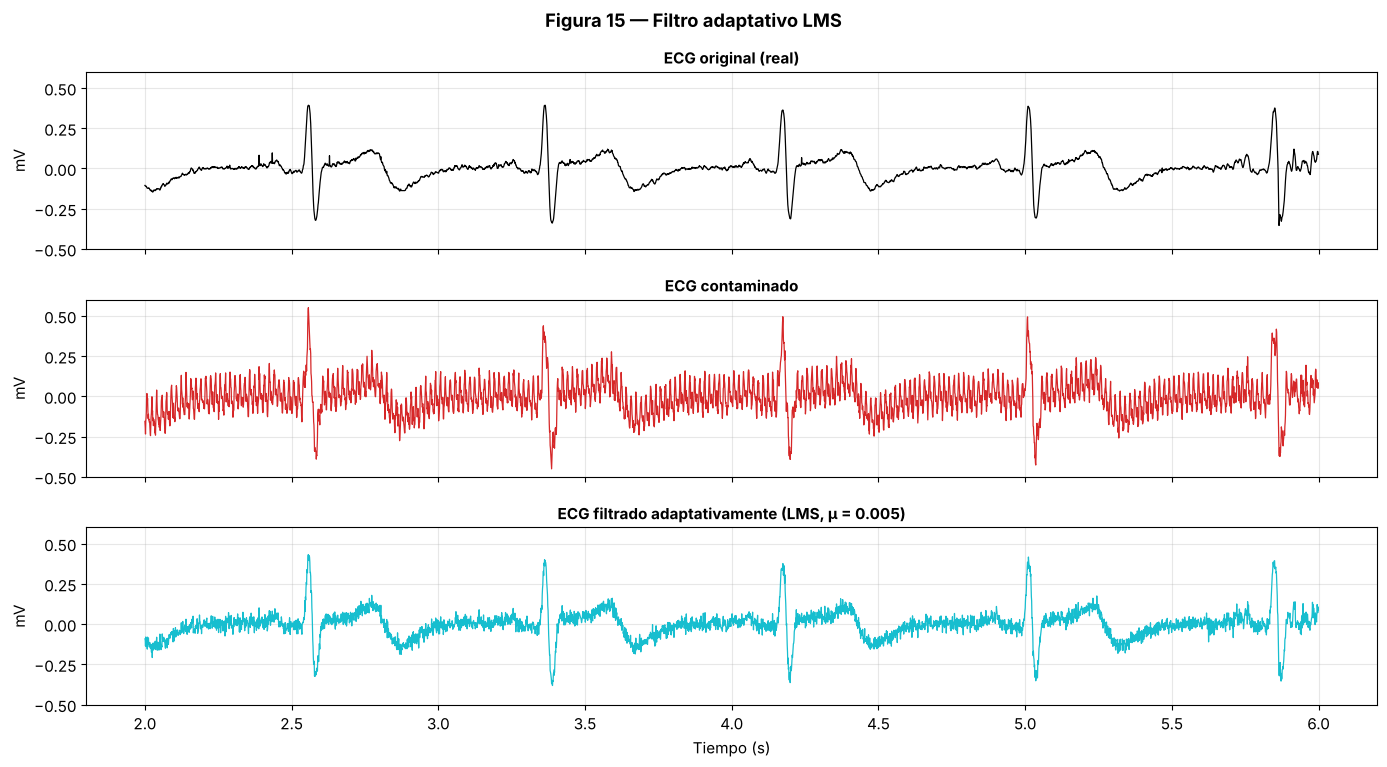

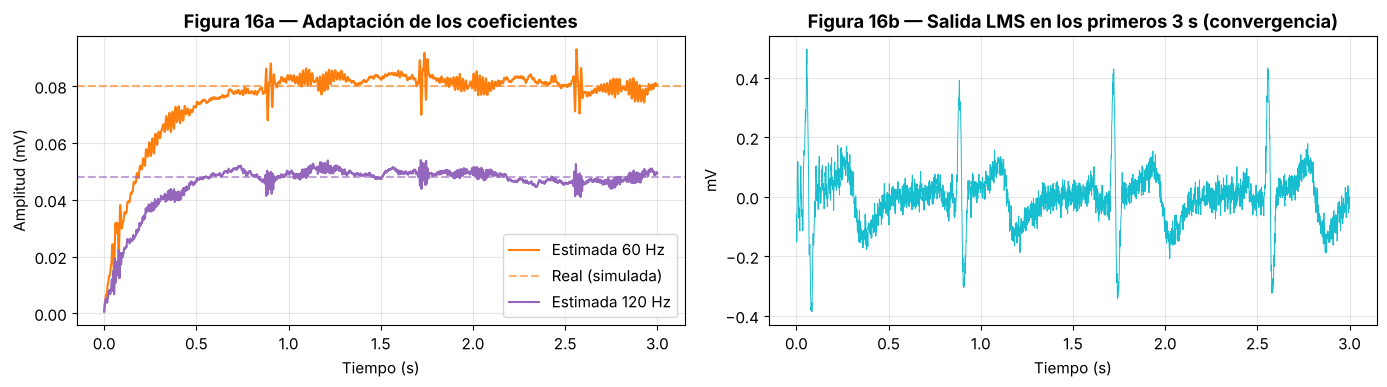

,RMSE (mV),SNR (dB),Correlación r
Contaminado (sin filtrar),0.0699,1.0894,0.7509
A — Pasa-banda,0.0092,18.7216,0.9933
B1 — Notch 60 Hz,0.0414,5.6416,0.8859
B2 — Notch 60+120 Hz,0.0239,10.4038,0.9572
LMS adaptativo,0.0244,10.2271,0.9564


In [25]:
comparar_senales([
    ("ECG original (real)", ecg_original, "black"),
    ("ECG contaminado", ecg_contaminado, "tab:red"),
    (f"ECG filtrado adaptativamente (LMS, μ = {MU})", ecg_lms, "tab:cyan"),
], "Figura 15 — Filtro adaptativo LMS")

# ¿Cómo "aprende" el filtro? Amplitud estimada de cada interferencia en el tiempo
amplitud_est_1 = np.hypot(pesos[:, 0], pesos[:, 1])
amplitud_est_2 = np.hypot(pesos[:, 2], pesos[:, 3])
primeros = t < 3.0

fig, ejes = plt.subplots(1, 2, figsize=(14, 4))
ejes[0].plot(t[primeros], amplitud_est_1[primeros], label=f"Estimada {f1} Hz", color="tab:orange")
ejes[0].axhline(amplitud_1, ls="--", color="tab:orange", alpha=0.6, label="Real (simulada)")
ejes[0].plot(t[primeros], amplitud_est_2[primeros], label=f"Estimada {f2} Hz", color="tab:purple")
ejes[0].axhline(amplitud_2, ls="--", color="tab:purple", alpha=0.6)
ejes[0].set_title("Figura 16a — Adaptación de los coeficientes")
ejes[0].set_xlabel("Tiempo (s)"); ejes[0].set_ylabel("Amplitud (mV)"); ejes[0].legend()

ejes[1].plot(t[primeros], ecg_lms[primeros], color="tab:cyan", lw=0.7)
ejes[1].set_title("Figura 16b — Salida LMS en los primeros 3 s (convergencia)")
ejes[1].set_xlabel("Tiempo (s)"); ejes[1].set_ylabel("mV")
plt.tight_layout(); plt.show()

resultados["LMS adaptativo"] = calcular_metricas(ecg_original, ecg_lms)
pd.DataFrame(resultados).T.round(4)

### 🔎 Interpretación — Filtro adaptativo

- Al inicio los coeficientes valen cero: la salida todavía contiene la interferencia. En unos cientos de milisegundos los coeficientes **convergen** a la amplitud real de cada interferencia (Figura 16a).
- Una vez adaptado, el LMS cancela $f_1$ y $f_2$ con muy poca alteración del ECG.
- El ruido gaussiano **permanece**: no está correlacionado con la referencia, así que el filtro no puede "aprenderlo".
- Su gran ventaja frente al notch aparece cuando la interferencia **cambia** (amplitud/fase variables): el LMS la sigue; el notch fijo no se entera.

### ❓ Pregunta al estudiante

Cambia `MU` a 0.0005 y a 0.05. ¿Qué pasa con la velocidad de convergencia (Figura 16a) y con la calidad de la señal?

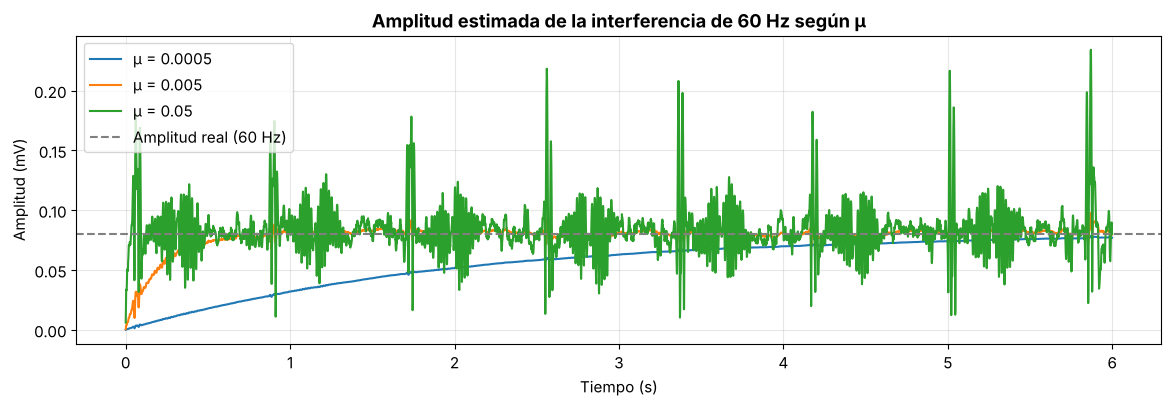

,Tiempo al 90 % de la amplitud de 60 Hz (s),Fluctuación de la amplitud estimada (mV),SNR (dB),RMSE (mV),SNR primeros 2 s (dB)
μ = 0.0005,4.468,0.0017,10.2008,0.0245,5.2486
μ = 0.005,0.385,0.0031,10.2271,0.0244,10.0522
μ = 0.05,0.024,0.0186,8.9300,0.0283,9.8436


In [26]:
# Verificación: efecto de μ (0.0005, 0.005, 0.05) sobre la convergencia y la calidad
fig, eje = plt.subplots(figsize=(14, 4))
filas = {}
for mu in (0.0005, 0.005, 0.05):
    e_mu, _, w_mu = filtro_lms(ecg_contaminado, referencias, mu)
    amp_60 = np.hypot(w_mu[:, 0], w_mu[:, 1])
    eje.plot(t[t < 6], amp_60[t < 6], label=f"μ = {mu}")
    t90 = t[np.argmax(amp_60 >= 0.9 * amplitud_1)]
    regimen = (t > 5) & (t < 30)
    ini = t < 2
    m = calcular_metricas(ecg_original, e_mu)
    filas[f"μ = {mu}"] = {
        "Tiempo al 90 % de la amplitud de 60 Hz (s)": t90,
        "Fluctuación de la amplitud estimada (mV)": amp_60[regimen].std(),
        "SNR (dB)": m["SNR (dB)"],
        "RMSE (mV)": m["RMSE (mV)"],
        "SNR primeros 2 s (dB)": 10 * np.log10(np.sum(ecg_original[ini] ** 2) / np.sum((e_mu[ini] - ecg_original[ini]) ** 2)),
    }
eje.axhline(amplitud_1, ls="--", color="gray", label="Amplitud real (60 Hz)")
eje.set_title("Amplitud estimada de la interferencia de 60 Hz según μ")
eje.set_xlabel("Tiempo (s)"); eje.set_ylabel("Amplitud (mV)"); eje.legend()
plt.show()
pd.DataFrame(filas).T.round(4)

✍️ **Respuesta:**

| μ | Convergencia (90 % de la amplitud real de 60 Hz) | Fluctuación de la amplitud estimada | SNR global | SNR en los primeros 2 s |
|---|---|---|---|---|
| 0.0005 | ≈ 4.5 s (lenta) | 0.0017 mV (muy estable) | 10.20 dB | 5.25 dB |
| 0.005 | ≈ 0.39 s | 0.0031 mV | 10.23 dB | 10.05 dB |
| 0.05 | ≈ 0.02 s (casi inmediata) | 0.0186 mV (ruidosa) | 8.93 dB | 9.84 dB |

- **μ pequeño (0.0005):** converge unas 12 veces más lento que con 0.005, y durante los primeros segundos el ECG sigue contaminado. Una vez adaptado, los coeficientes son muy estables (más precisión).
- **μ grande (0.05):** converge casi al instante, pero los coeficientes **fluctúan** (≈ 6 veces más que con 0.005) y esa fluctuación se cuela en la salida: el SNR baja a 8.93 dB y el RMSE sube a 0.0283 mV. El filtro sigue siendo estable, pero distorsiona más el ECG.
- El SNR global casi no distingue 0.0005 de 0.005 porque las métricas excluyen los primeros 2 s (ver la columna de los primeros 2 s). μ = 0.005 es el compromiso entre rapidez y precisión.

## 5.2 Transformada Wavelet

¿Para qué sirve la Transformada Wavelet en el procesamiento de señales biomédicas?

La FFT nos dice **qué** frecuencias hay en la señal, pero **no cuándo** aparecen (analiza la señal completa de forma global). La **Transformada Wavelet** descompone la señal usando pequeñas "ondas" (wavelets) de duración limitada, a distintas **escalas**:

- **Escalas pequeñas** → detalles rápidos (alta frecuencia), bien localizados en el tiempo.
- **Escalas grandes** → tendencias lentas (baja frecuencia).

Esto encaja muy bien con el ECG:

- el complejo **QRS** es un evento rápido y localizado;
- las ondas **P** y **T** son más lentas;
- el **ruido** suele dispersarse en los detalles finos con coeficientes pequeños;
- la **deriva de base** vive en la aproximación más gruesa.

### Descomposición Wavelet Discreta (DWT)

En cada nivel la señal se divide en una **aproximación** (A, parte lenta) y un **detalle** (D, parte rápida); la aproximación se vuelve a dividir:

```
Señal ─┬─► D1 (Fs/4 – Fs/2)
       └─► A1 ─┬─► D2 (Fs/8 – Fs/4)
               └─► A2 ─┬─► D3 ...
                       └─► ... ─► A_L (la parte más lenta)
```

Usaremos la wavelet **Daubechies 4** (`db4`), muy empleada en ECG porque su forma se parece a la de un complejo QRS.

In [27]:
WAVELET = "db4"
nivel_max = pywt.dwt_max_level(len(ecg_original), pywt.Wavelet(WAVELET).dec_len)
NIVEL = min(8, nivel_max)

# Banda de frecuencias aproximada de cada nivel
print(f"Wavelet: {WAVELET} | Niveles: {NIVEL}\n")
print(f"A{NIVEL}: 0 – {Fs / 2**(NIVEL+1):.1f} Hz (aproximación)")
for j in range(NIVEL, 0, -1):
    print(f"D{j}: {Fs / 2**(j+1):.1f} – {Fs / 2**j:.1f} Hz")
print(f"\nInterferencia 1 ({f1} Hz) y 2 ({f2} Hz): ubícalas en la tabla anterior.")

def componentes_por_nivel(x, wavelet, nivel):
    """Reconstruye por separado la contribución de la aproximación y de cada detalle (en el dominio del tiempo)."""
    coefs = pywt.wavedec(x, wavelet, level=nivel)
    componentes = {}
    nombres = [f"A{nivel}"] + [f"D{j}" for j in range(nivel, 0, -1)]
    for i, nombre in enumerate(nombres):
        coefs_solo = [c if k == i else np.zeros_like(c) for k, c in enumerate(coefs)]
        componentes[nombre] = pywt.waverec(coefs_solo, wavelet)[:len(x)]
    return componentes

comp_original = componentes_por_nivel(ecg_original, WAVELET, NIVEL)
comp_contaminado = componentes_por_nivel(ecg_contaminado, WAVELET, NIVEL)

Wavelet: db4 | Niveles: 8

A8: 0 – 2.0 Hz (aproximación)
D8: 2.0 – 3.9 Hz
D7: 3.9 – 7.8 Hz
D6: 7.8 – 15.6 Hz
D5: 15.6 – 31.2 Hz
D4: 31.2 – 62.5 Hz
D3: 62.5 – 125.0 Hz
D2: 125.0 – 250.0 Hz
D1: 250.0 – 500.0 Hz

Interferencia 1 (60 Hz) y 2 (120 Hz): ubícalas en la tabla anterior.


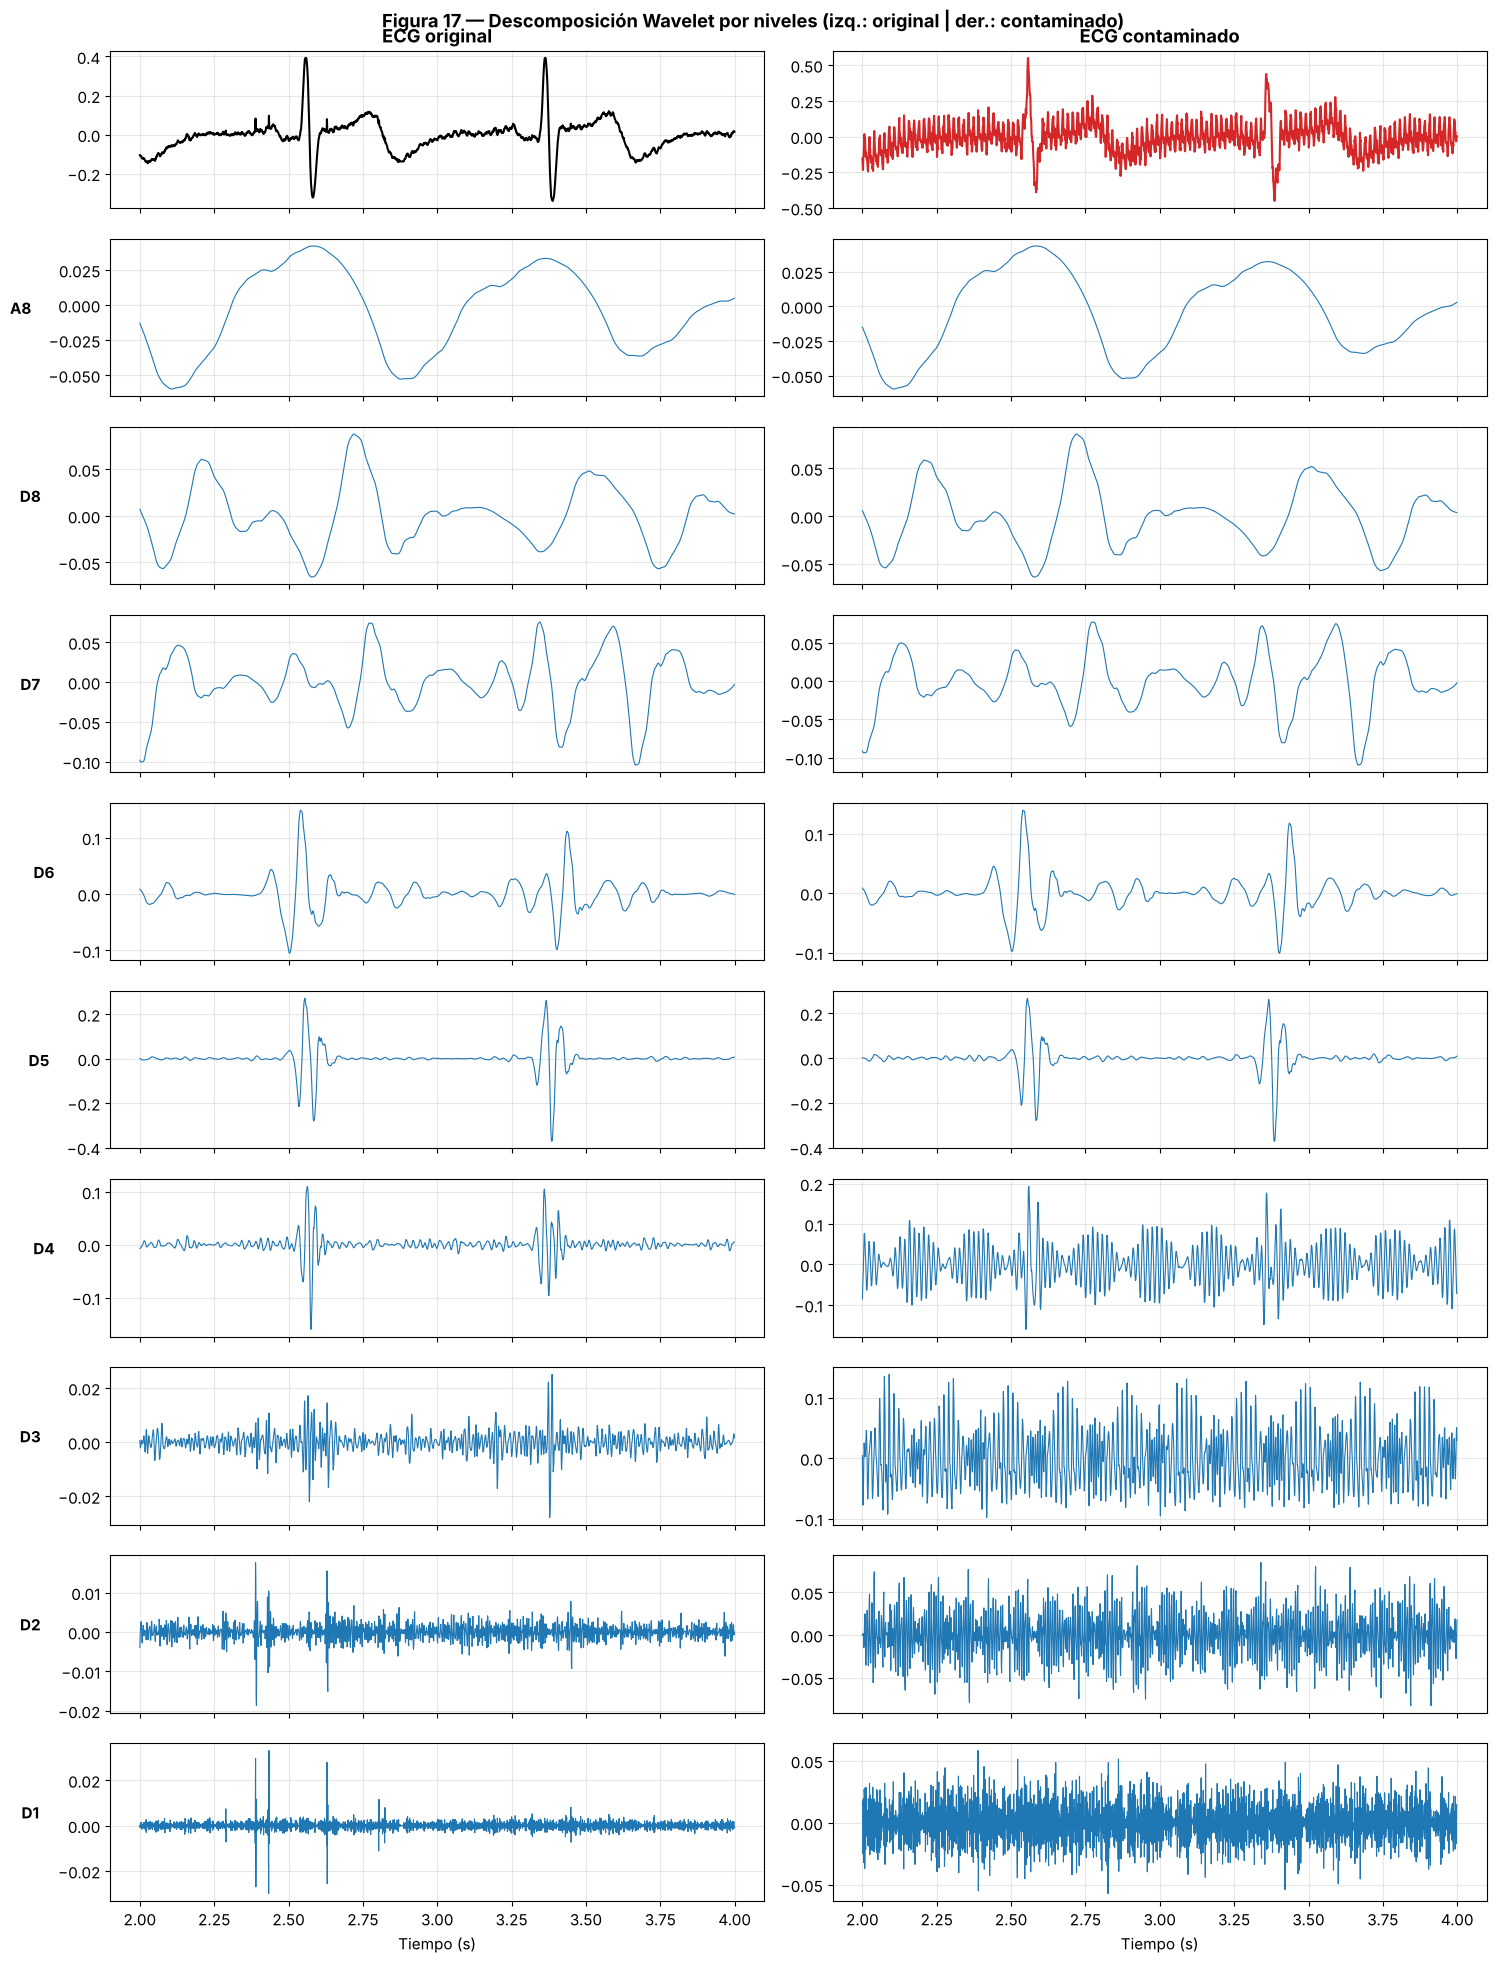

In [28]:
ventana_2s = (t >= T_INICIO_ZOOM) & (t < T_INICIO_ZOOM + 2.0)
nombres = list(comp_original.keys())

fig, ejes = plt.subplots(len(nombres) + 1, 2, figsize=(15, 2 * (len(nombres) + 1)), sharex=True)
ejes[0, 0].plot(t[ventana_2s], ecg_original[ventana_2s], color="black"); ejes[0, 0].set_title("ECG original")
ejes[0, 1].plot(t[ventana_2s], ecg_contaminado[ventana_2s], color="tab:red"); ejes[0, 1].set_title("ECG contaminado")
for i, nombre in enumerate(nombres, start=1):
    ejes[i, 0].plot(t[ventana_2s], comp_original[nombre][ventana_2s], color="tab:blue", lw=0.8)
    ejes[i, 1].plot(t[ventana_2s], comp_contaminado[nombre][ventana_2s], color="tab:blue", lw=0.8)
    ejes[i, 0].set_ylabel(nombre, rotation=0, labelpad=20, fontweight="bold")
ejes[-1, 0].set_xlabel("Tiempo (s)"); ejes[-1, 1].set_xlabel("Tiempo (s)")
fig.suptitle("Figura 17 — Descomposición Wavelet por niveles (izq.: original | der.: contaminado)", fontweight="bold")
plt.tight_layout(); plt.show()

### 🔎 Interpretación — Descomposición

- **D1, D2** (frecuencias altas): en el original casi no hay energía; en el contaminado aparecen dominados por **ruido gaussiano**.
- **D3, D4**: aquí "caen" las interferencias de 120 Hz y 60 Hz (oscilaciones regulares).
- **D5 – D7**: contienen la energía de los **complejos QRS** (picos localizados en el tiempo).
- **A8 (aproximación)**: tendencia lenta y **deriva de línea de base**.
- Observa que en los detalles el QRS aparece **localizado en el tiempo**: eso es lo que la FFT global no puede mostrar.

## 5.3 Denoising mediante Wavelet (umbralización)

Idea: los eventos importantes (QRS) producen **pocos coeficientes grandes**; el ruido produce **muchos coeficientes pequeños**. Entonces:

1. Descomponer la señal (DWT).
2. Estimar el nivel de ruido con el detalle más fino: $\sigma = \text{mediana}(|D_1|)/0.6745$.
3. Calcular un umbral (universal): $\lambda = \sigma\sqrt{2\ln N}$.
4. **Umbralizar** los detalles: los coeficientes con $|c| < \lambda$ se anulan, los demás se reducen (*soft thresholding*).
5. Reconstruir la señal (IDWT).

Umbral universal aplicado: 0.1105


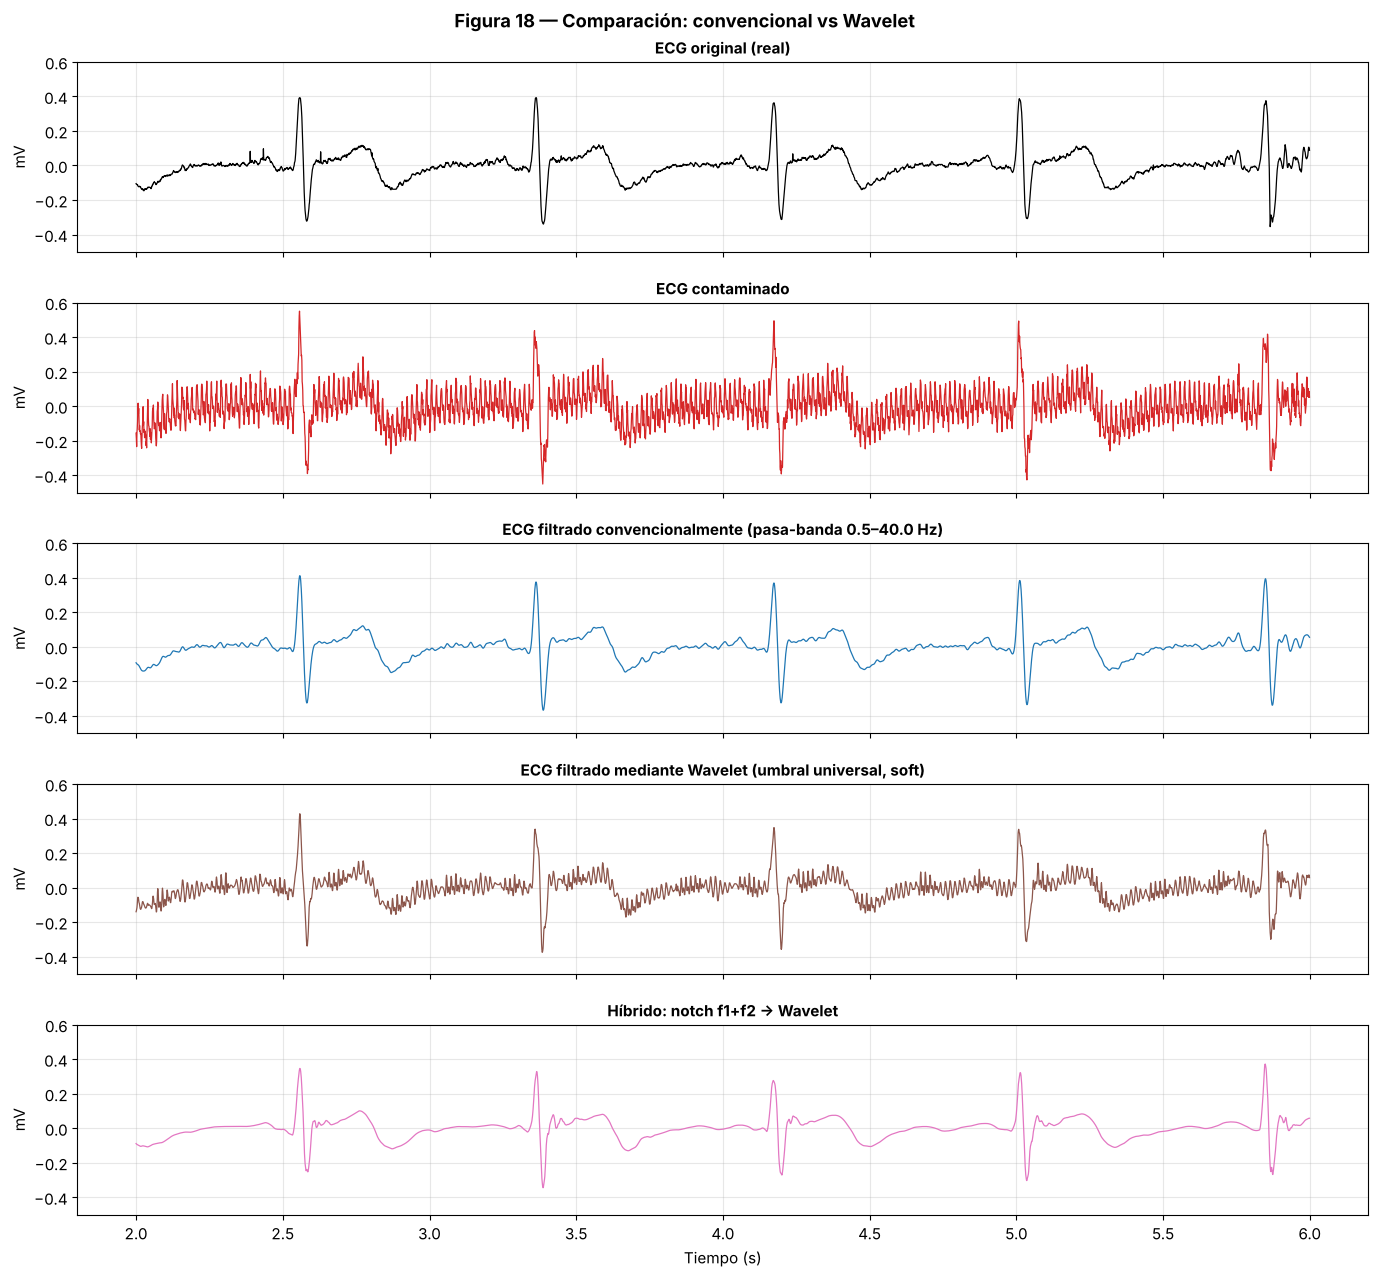

,RMSE (mV),SNR (dB),Correlación r
Contaminado (sin filtrar),0.0699,1.0894,0.7509
A — Pasa-banda,0.0092,18.7216,0.9933
B1 — Notch 60 Hz,0.0414,5.6416,0.8859
B2 — Notch 60+120 Hz,0.0239,10.4038,0.9572
LMS adaptativo,0.0244,10.2271,0.9564
Wavelet (denoising),0.0332,7.5614,0.9083
Híbrido notch + Wavelet,0.0194,12.2093,0.9779


In [29]:
def denoising_wavelet(x, wavelet=WAVELET, nivel=NIVEL, modo="soft"):
    coefs = pywt.wavedec(x, wavelet, level=nivel)
    sigma = np.median(np.abs(coefs[-1])) / 0.6745               # ruido estimado a partir de D1
    umbral = sigma * np.sqrt(2 * np.log(len(x)))                # umbral universal
    coefs_umbral = [coefs[0]] + [pywt.threshold(c, umbral, mode=modo) for c in coefs[1:]]
    x_limpia = pywt.waverec(coefs_umbral, wavelet)[:len(x)]
    return x_limpia, umbral

# 1) Wavelet aplicada directamente a la señal contaminada
ecg_wavelet, umbral = denoising_wavelet(ecg_contaminado)

# 2) Enfoque híbrido: primero notch (quita interferencias), luego wavelet (quita ruido gaussiano)
ecg_hibrido, _ = denoising_wavelet(ecg_notch_f1f2)

print(f"Umbral universal aplicado: {umbral:.4f}")

comparar_senales([
    ("ECG original (real)", ecg_original, "black"),
    ("ECG contaminado", ecg_contaminado, "tab:red"),
    (f"ECG filtrado convencionalmente (pasa-banda {fc_baja}–{fc_alta} Hz)", ecg_pasabanda, "tab:blue"),
    ("ECG filtrado mediante Wavelet (umbral universal, soft)", ecg_wavelet, "tab:brown"),
    ("Híbrido: notch f1+f2 → Wavelet", ecg_hibrido, "tab:pink"),
], "Figura 18 — Comparación: convencional vs Wavelet")

resultados["Wavelet (denoising)"] = calcular_metricas(ecg_original, ecg_wavelet)
resultados["Híbrido notch + Wavelet"] = calcular_metricas(ecg_original, ecg_hibrido)
pd.DataFrame(resultados).T.round(4)

### 🔎 Interpretación — *Denoising* Wavelet

- La umbralización **reduce eficazmente el ruido gaussiano** (banda ancha, coeficientes pequeños) y tiende a **conservar los QRS**, porque sus coeficientes son grandes.
- Sin embargo, las **interferencias sinusoidales intensas** generan coeficientes grandes en D3–D4 que **superan el umbral** → pueden sobrevivir al *denoising*. La Wavelet no es la herramienta ideal para una interferencia de banda estrecha.
- El enfoque **híbrido** combina fortalezas: el notch quita las interferencias y la Wavelet el ruido de banda ancha.
- **Posibles distorsiones:** el *soft thresholding* reduce ligeramente la amplitud de los picos y puede generar pequeñas oscilaciones cerca de los QRS.

### ❓ Pregunta al estudiante

Cambia `modo="soft"` por `modo="hard"` y prueba la wavelet `"sym8"` en lugar de `"db4"`. ¿Cómo cambian la forma del QRS y las métricas?

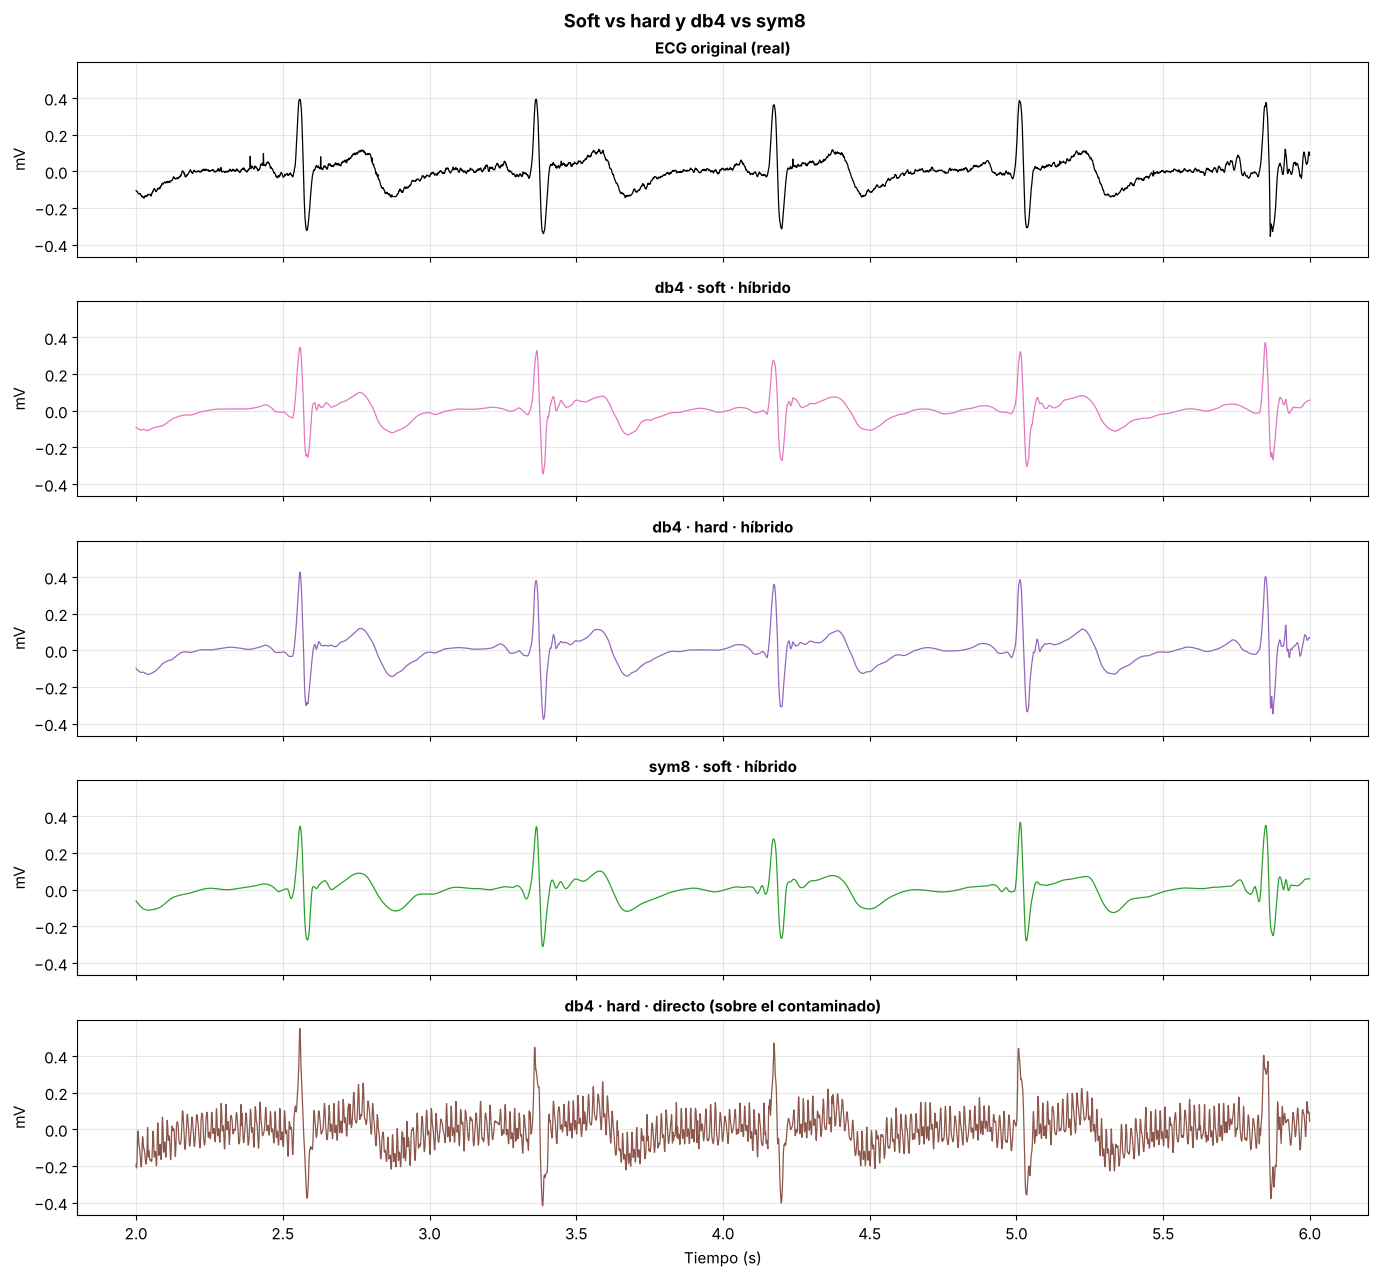

,Altura media de R (mV),RMSE (mV),SNR (dB),Correlación r
ECG original (referencia),0.3564,NaN,NaN,NaN
db4 · soft · directo,0.3141,0.0332,7.5614,0.9083
db4 · soft · híbrido,0.3070,0.0194,12.2093,0.9779
db4 · hard · directo,0.3641,0.0599,2.4371,0.7961
db4 · hard · híbrido,0.3647,0.0114,16.8627,0.9897
sym8 · soft · directo,0.3159,0.0337,7.4296,0.9056
sym8 · soft · híbrido,0.3078,0.0194,12.2055,0.9771
sym8 · hard · directo,0.3620,0.0611,2.2543,0.7897
sym8 · hard · híbrido,0.3613,0.0117,16.6374,0.9891


In [30]:
# Verificación: modo soft/hard y wavelet db4/sym8 (directo = sobre el contaminado; híbrido = notch → wavelet)
filas = {"ECG original (referencia)": {"Altura media de R (mV)": ecg_original[picos].mean()}}
variantes = {}
for wv in ("db4", "sym8"):
    for modo in ("soft", "hard"):
        directo, _ = denoising_wavelet(ecg_contaminado, wavelet=wv, modo=modo)
        hibrido, _ = denoising_wavelet(ecg_notch_f1f2, wavelet=wv, modo=modo)
        variantes[(wv, modo)] = (directo, hibrido)
        for nombre, s in (("directo", directo), ("híbrido", hibrido)):
            filas[f"{wv} · {modo} · {nombre}"] = {**calcular_metricas(ecg_original, s), "Altura media de R (mV)": s[picos].mean()}

comparar_senales([
    ("ECG original (real)", ecg_original, "black"),
    ("db4 · soft · híbrido", variantes[("db4", "soft")][1], "tab:pink"),
    ("db4 · hard · híbrido", variantes[("db4", "hard")][1], "tab:purple"),
    ("sym8 · soft · híbrido", variantes[("sym8", "soft")][1], "tab:green"),
    ("db4 · hard · directo (sobre el contaminado)", variantes[("db4", "hard")][0], "tab:brown"),
], "Soft vs hard y db4 vs sym8")
pd.DataFrame(filas).T.round(4)

✍️ **Respuesta:**

- **Forma del QRS (soft vs hard):** con `soft` los picos R salen más bajos (altura media 0.314 mV frente a 0.356 mV del original, ≈ −12 %) porque el umbral "encoge" los coeficientes grandes. Con `hard` se conserva la altura (≈ 0.36 mV).
- **Métricas, Wavelet directa:** `hard` empeora mucho (db4: SNR 2.44 dB y r = 0.796 vs 7.56 dB y r = 0.908 con `soft`), probablemente porque deja intactos los coeficientes grandes de la interferencia de 60/120 Hz (el `soft` al menos los reduce en el valor del umbral); esta explicación es mecánica, no la medí por separado.
- **Métricas, enfoque híbrido (notch → Wavelet):** aquí `hard` es mejor (SNR 16.86 dB, r = 0.990 frente a 12.21 dB y r = 0.978 con `soft`): sin interferencias, ya no deja coeficientes indeseados y no recorta el QRS.
- **db4 vs sym8:** casi idénticas en este registro (diferencias ≤ 0.25 dB: p. ej. soft directo 7.56 dB con db4 y 7.43 dB con sym8; híbrido hard 16.86 dB y 16.64 dB). El tipo de umbral importa mucho más que la elección de wavelet.

---
# 🟦 BLOQUE 6 — Comparación e interpretación *(10 min)* · 🔁 Retroalimentación

> A partir de aquí **no se introducen conceptos nuevos**: revisamos, comparamos y discutimos.

,RMSE (mV),SNR (dB),Correlación r,Mejora SNR vs contaminado (dB)
A — Pasa-banda,0.0092,18.7216,0.9933,17.6322
Híbrido notch + Wavelet,0.0194,12.2093,0.9779,11.1200
B2 — Notch 60+120 Hz,0.0239,10.4038,0.9572,9.3144
LMS adaptativo,0.0244,10.2271,0.9564,9.1378
Wavelet (denoising),0.0332,7.5614,0.9083,6.4720
B1 — Notch 60 Hz,0.0414,5.6416,0.8859,4.5522
Contaminado (sin filtrar),0.0699,1.0894,0.7509,0.0000


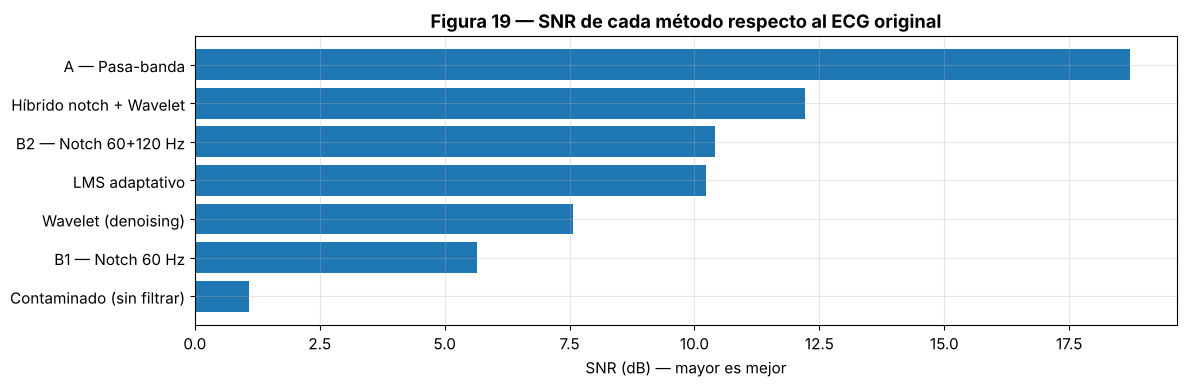

In [31]:
tabla_final = pd.DataFrame(resultados).T
tabla_final["Mejora SNR vs contaminado (dB)"] = tabla_final["SNR (dB)"] - tabla_final.loc["Contaminado (sin filtrar)", "SNR (dB)"]
display(tabla_final.round(4).sort_values("SNR (dB)", ascending=False))

# Gráfico de barras de SNR
plt.figure(figsize=(12, 4))
orden = tabla_final.sort_values("SNR (dB)")
plt.barh(orden.index, orden["SNR (dB)"], color="tab:blue")
plt.xlabel("SNR (dB) — mayor es mejor")
plt.title("Figura 19 — SNR de cada método respecto al ECG original")
plt.tight_layout(); plt.show()

In [32]:
# Chequeo para completar la tabla: altura media de R y distorsión de cada método
señales = {
    "ECG original": ecg_original,
    "Pasa-banda": ecg_pasabanda,
    "Notch f1+f2": ecg_notch_f1f2,
    "LMS adaptativo": ecg_lms,
    "Wavelet (soft)": ecg_wavelet,
    "Híbrido (soft)": ecg_hibrido,
}
r_ref = ecg_original[picos].mean()
tabla_R = pd.DataFrame({
    nombre: {"Altura media de R (mV)": s[picos].mean(), "Cambio vs original (%)": 100 * (s[picos].mean() / r_ref - 1)}
    for nombre, s in señales.items()
}).T
tabla_R.round(3)

,Altura media de R (mV),Cambio vs original (%)
ECG original,0.356,0.000
Pasa-banda,0.358,0.338
Notch f1+f2,0.353,-0.864
LMS adaptativo,0.356,-0.209
Wavelet (soft),0.314,-11.875
Híbrido (soft),0.307,-13.855


### Comparación cualitativa (completada con los resultados de este registro)

| Criterio | Pasa-banda | Notch | LMS adaptativo | Wavelet | Híbrido |
|---|---|---|---|---|---|
| Reducción de interferencias | Alta (60 y 120 Hz quedan fuera de la banda) | Alta, pero solo en las frecuencias indicadas (B1 deja 120 Hz) | Alta tras converger | Baja: las interferencias intensas sobreviven en D3–D4 | Alta (la quita el notch) |
| Reducción de ruido gaussiano | Parcial: quita lo que cae fuera de 0.5–40 Hz (≈ 92 %) | Ninguna | Ninguna | Alta | Alta |
| Conservación de la morfología | Buena (r = 0.993) | Muy buena (r = 0.999 sobre el original) | Muy buena (R medio sin cambio: −0.2 %) | Regular: R ≈ −12 % con soft | Buena (r = 0.978); R ≈ −14 % con soft |
| Distorsión introducida | Media (RMSE 0.0065 mV sobre el original) | Mínima (RMSE 0.0027 mV) | Mínima tras converger; transitorio inicial | Media (soft reduce los picos) | Media con soft; baja con hard |
| Complejidad | Baja | Baja | Media | Media | Media |
| ¿Qué necesita conocer? | Banda del ECG | Frecuencia exacta | Señal de referencia | Wavelet, niveles, umbral | Ambos |

> ⚖️ **Ningún método es universalmente superior.** La elección depende del tipo de contaminación, de qué información fisiológica debe conservarse y de la aplicación (monitoreo, diagnóstico, detección de QRS, tiempo real…).

---
# 🟦 BLOQUE 7 — Retroalimentación, síntesis e infografía *(15 min)*

## 📝 Actividad de análisis

Responde de forma breve y justificada (2 – 4 líneas por pregunta).

**Pregunta 1.** ¿Por qué es importante conocer la frecuencia de muestreo de una señal biomédica?

✍️ **Respuesta:** Porque determina cuántas muestras se registran por segundo y qué frecuencias podemos analizar sin que aparezca aliasing. En nuestro caso, utilizamos una frecuencia de 1000 Hz, lo que nos permitió representar correctamente el ECG y aplicar los filtros digitales.

**Pregunta 2.** ¿Qué diferencia existe entre ruido e interferencia?

✍️ **Respuesta:** El ruido suele ser aleatorio y puede distribuirse en un amplio rango de frecuencias, como el ruido gaussiano. En cambio, la interferencia tiene un origen y comportamiento más definidos, como las señales sinusoidales de 60 y 120 Hz que agregamos al ECG.

**Pregunta 3.** ¿Por qué una interferencia sinusoidal puede observarse como un pico en el dominio de la frecuencia?

✍️ **Respuesta:** Porque una señal sinusoidal concentra su energía en una frecuencia específica. Al aplicar la FFT, esta energía se representa como un pico en el espectro, tal como observamos con las interferencias de 60 y 120 Hz que añadimos a la señal.

**Pregunta 4.** ¿Qué sucede cuando aplicamos un filtro demasiado agresivo a una señal ECG? *(Sugerencia: prueba `fc_alta = 15` en el Experimento A y observa el QRS.)*

✍️ **Respuesta:** Un filtro demasiado agresivo puede eliminar componentes importantes del ECG junto con el ruido. Por ejemplo, al reducir la frecuencia de corte superior a 15 Hz, se esperaría una atenuación de los componentes rápidos del QRS, haciendo que los picos se vean más redondeados y perdiendo detalles de su morfología.

**Pregunta 5.** ¿Cuál es la principal diferencia conceptual entre un filtro convencional y un filtro adaptativo?

✍️ **Respuesta:** Un filtro convencional utiliza coeficientes fijos que no cambian durante el procesamiento. En cambio, un filtro adaptativo, como el LMS utilizado en el laboratorio, ajusta sus coeficientes continuamente para estimar y reducir interferencias que pueden variar con el tiempo.

**Pregunta 6.** ¿Para qué sirve la Transformada Wavelet?

✍️ **Respuesta:** Sirve para descomponer una señal en componentes de diferentes escalas, permitiendo analizar cómo cambian sus características en el tiempo y la frecuencia. También puede utilizarse para reducir ruido mediante la modificación de los coeficientes de la descomposición.

**Pregunta 7.** ¿Por qué la Transformada Wavelet puede resultar útil para analizar señales biomédicas?

✍️ **Respuesta:** Porque las señales biomédicas presentan cambios rápidos y eventos localizados en el tiempo, como los complejos QRS del ECG. Wavelet permite identificar estos eventos en distintas escalas y reducir el ruido, procurando conservar la información fisiológica importante.

**Pregunta 8.** ¿Qué información podría perderse durante el proceso de filtrado?

✍️ **Respuesta:** Podrían perderse componentes de la señal que compartan frecuencias con el ruido eliminado. En el ECG, esto puede provocar una reducción de la amplitud de los picos R, pérdida de detalles del QRS o alteraciones de las ondas P y T, afectando su interpretación.

**Pregunta 9.** Si conoces la frecuencia exacta de una interferencia, ¿qué tipo de filtro podrías utilizar?

✍️ **Respuesta:** Utilizaría un filtro notch, porque permite atenuar una frecuencia específica sin modificar demasiado las demás componentes. En el laboratorio aplicamos filtros notch de 60 y 120 Hz para eliminar las interferencias sinusoidales introducidas artificialmente.

**Pregunta 10.** ¿Por qué no debemos evaluar un filtro únicamente observando visualmente la señal?

✍️ **Respuesta:** Porque una señal puede verse más limpia, pero haber perdido información importante durante el filtrado. Por eso también debemos comparar métricas como SNR, RMSE y correlación, que permiten evaluar cuantitativamente la reducción del ruido y la conservación de la señal original.

## 🧠 SUMARIZE — ¿Qué aprendimos?

Resume en pocas líneas:

```text
1. ¿Qué problema tenía la señal?
2. ¿Cómo contaminamos la señal?
3. ¿Qué filtro utilizamos?
4. ¿Qué resultado obtuvimos?
5. ¿Para qué sirve un filtro adaptativo?
6. ¿Para qué sirve Wavelet?
7. ¿Qué método utilizarías y por qué?
```

✍️ **Respuesta:**
```text
1. Trabajamos con una señal ECG real que fue contaminada artificialmente con ruido e interferencias, dificultando la identificación de sus componentes, especialmente las ondas de menor amplitud.
2. Añadimos dos interferencias sinusoidales de 60 y 120 Hz, además de ruido gaussiano aleatorio, para simular condiciones que afectan la calidad de una señal ECG.
3. Probamos un filtro pasa-banda Butterworth de 0.5–40 Hz, filtros notch de 60 y 120 Hz, un filtro adaptativo LMS y filtrado mediante Wavelet. También evaluamos una combinación de notch y Wavelet.
4. Todos los métodos mejoraron la señal en diferente medida. El pasa-banda obtuvo el mejor resultado cuantitativo, aumentando la SNR de 1.09 dB a 18.72 dB, con una correlación de 0.993 respecto al ECG original.
5. Permite reducir interferencias ajustando sus coeficientes automáticamente según la señal recibida. Es especialmente útil cuando la amplitud o fase de la interferencia cambia con el tiempo, siempre que se disponga de una referencia adecuada.
6. Permite analizar la señal en diferentes escalas de tiempo y frecuencia, identificar eventos como los complejos QRS y reducir ruido mediante umbralización, aunque este proceso también puede modificar la amplitud de los picos.
7. Para este experimento utilizaría el filtro pasa-banda de 0.5–40 Hz, porque obtuvo la mayor SNR (18.72 dB), el menor RMSE (0.0092 mV) y una buena conservación de la morfología del ECG. Sin embargo, elegiría otro método si necesitara conservar más componentes de alta frecuencia o tratar interferencias variables.
```

## ✅ Conclusiones del laboratorio

✍️ Escribe tus conclusiones (5 – 8 líneas), considerando: reducción del ruido, conservación de la morfología, distorsión, complejidad y aplicación biomédica.

✍️ **Conclusiones:**

En este laboratorio se comprobó que los filtros digitales permiten reducir el ruido y las interferencias presentes en una señal ECG, mejorando su calidad.
El filtro pasa-banda Butterworth de 0.5–40 Hz obtuvo los mejores resultados, aumentando la SNR de 1.09 dB a 18.72 dB y conservando adecuadamente la morfología de la señal.
Sin embargo, observamos que un filtrado demasiado agresivo puede eliminar información importante y producir distorsiones en las ondas del ECG, especialmente en el complejo QRS.
Por otro lado, el filtro adaptativo LMS permite ajustarse a interferencias variables, aunque requiere una referencia adecuada y mayor complejidad de implementación.
La Transformada Wavelet permitió reducir el ruido mediante el análisis de diferentes escalas, pero también puede modificar la amplitud de algunos picos.
Finalmente, concluimos que no existe un filtro ideal para todas las situaciones, por lo que su elección debe considerar la reducción del ruido, la conservación de la información fisiológica y las necesidades de cada aplicación biomédica.
